In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from dataclasses import dataclass
import torchvision.utils as vutils
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score,f1_score
import networkx as nx
from sklearn.preprocessing import MinMaxScaler,StandardScaler
import time

In [2]:
# model = AERNN(46572, train_X.shape[1], 256 , 8)
# # model.apply(bias_init)
# # model = model.to(device)

# optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
# loss_fn = nn.MSELoss()

In [3]:
# def extract_graph_features(df, G):
#     # Pre-calculate degree dicts for speed
#     degrees = dict(G.degree())
    
#     src_degrees = []
#     tgt_degrees = []
#     common_neighbors = []
    
#     for src, tgt in zip(df['source'], df['target']):
#         src_degrees.append(degrees.get(src, 0))
#         tgt_degrees.append(degrees.get(tgt, 0))
        
#         # Intersection of neighbors
#         if G.has_node(src) and G.has_node(tgt):
#             cn = len(list(set(G.successors(src)) & set(G.successors(tgt))))        
#         else:
#             cn = 0
#         common_neighbors.append(cn)
        
#     df['src_degree'] = src_degrees
#     df['tgt_degree'] = tgt_degrees
#     df['common_neighbors'] = common_neighbors
#     return df

In [4]:
def extract_graph_features(df, G):
    # Pre-calculate degree dicts
    degrees = dict(G.degree())
    in_degrees = dict(G.in_degree())
    out_degrees = dict(G.out_degree())
    
    src_degrees, tgt_degrees = [], []
    src_in_grads, tgt_out_grads = [], []
    common_neighbors = []
    jaccard_coeffs = []
    
    # 1. Advanced Structural Features
    for src, tgt in zip(df['source'], df['target']):
        src_degrees.append(degrees.get(src, 0))
        tgt_degrees.append(degrees.get(tgt, 0))
        src_in_grads.append(in_degrees.get(src, 0))
        tgt_out_grads.append(out_degrees.get(tgt, 0))
        
        if G.has_node(src) and G.has_node(tgt):
            preds = set(G.successors(src))
            succs = set(G.successors(tgt))
            cn = len(preds & succs)
            union = len(preds | succs)
            jaccard = cn / union if union > 0 else 0
        else:
            cn, jaccard = 0, 0
            
        common_neighbors.append(cn)
        jaccard_coeffs.append(jaccard)
        
    df['src_degree'] = src_degrees
    df['tgt_degree'] = tgt_degrees
    df['src_in_degree'] = src_in_grads
    df['tgt_out_degree'] = tgt_out_grads
    df['common_neighbors'] = common_neighbors
    df['jaccard_coefficient'] = jaccard_coeffs
    
    # 2. Temporal Features (Crucial for DARPA)
    # Calculate time differentials between successive connections per source node
    df = df.sort_values("timeStamp").reset_index(drop=True)
    df['time_diff_src'] = df.groupby('source')['timeStamp'].diff().fillna(0)
    
    # Rolling frequency windows (e.g., number of connections in the last 100 operations)
    df['src_rolling_count'] = df.groupby('source').cumcount()
    
    return df

In [5]:
# raw_data = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_edges.txt",names=["source","target","timeStamp"])
# # print(raw_data)
# data_y = pd.read_csv("/Users/tony/Downloads/Graph-Sketch/data/DARPA/darpa_ground_truth.csv")
# raw_data_no_strings = raw_data.drop(0)
# raw_data_no_strings = raw_data_no_strings.drop(columns="timeStamp")
# tensor_array = torch.tensor(raw_data_no_strings.values)
# edge_list = tensor_array.numpy()
# Graph = nx.DiGraph()
# Graph.add_edges_from(edge_list)
# # nx.draw(Graph)

# final_graph = extract_graph_features(raw_data,Graph)
# train_x_data,test_x_data,train_y_data, test_y_data = train_test_split(raw_data,data_y,test_size=0.3)
# # raw_data == data_y
# filtered_data = train_x_data.copy()

# filtered_data["anamoly"] = train_y_data
# print(len(filtered_data))
# filtered_data = filtered_data[filtered_data["anamoly"]!=1]
# print(len(filtered_data))

# filtered_data = filtered_data.drop(columns=["anamoly"])
# data_X_tree_data = torch.tensor(raw_data.values,dtype=torch.float32)
# train_X = torch.tensor(filtered_data.values,dtype=torch.float32)

# data_Y = torch.tensor(data_y.values,dtype=torch.float32)

In [6]:
def balance_eval_set(df, anomaly_ratio=0.20):
    """Downsamples anomalies to ensure a realistic, challenging evaluation mix"""
    benign = df[df["anomaly"] == 0]
    anomalies = df[df["anomaly"] == 1]
    
    if len(anomalies) == 0 or len(benign) == 0:
        return df # Can't balance if one class is entirely missing
        
    # Calculate how many anomalies to keep to hit the target ratio
    target_anomaly_count = int((len(benign) * anomaly_ratio) / (1 - anomaly_ratio))
    
    # Safely cap it if we don't have enough anomalies
    target_anomaly_count = min(target_anomaly_count, len(anomalies))
    
    sampled_anomalies = anomalies.sample(n=target_anomaly_count, random_state=42)
    balanced_df = pd.concat([benign, sampled_anomalies]).sort_values("timeStamp").reset_index(drop=True)
    return balanced_df



In [7]:
import networkx as nx
import pandas as pd
import torch

# 1. Load data correctly
raw_data = pd.read_csv(
    "/Users/tony/Downloads/Graph-Sketch/data/DDOS2019/Data.csv",
    names=["source", "target", "timeStamp"],
    header=0,
)
data_y = pd.read_csv(
    "/Users/tony/Downloads/Graph-Sketch/data/DDOS2019/Label.csv",
    header=0,
)


# 2. Ensure they are aligned and sorted chronologically
# Attach the labels to raw_data immediately to keep everything aligned during sorting
raw_data["anomaly"] = data_y.iloc[:, 0].values  # Assuming ground truth is the first column
raw_data = raw_data.sort_values("timeStamp").reset_index(drop=True)

# 3. Build the graph safely using just edge lists
edge_list = raw_data[["source", "target"]].values
Graph = nx.DiGraph()
Graph.add_edges_from(edge_list)

# 4. Extract features
# Ensure your function handles/preserves the 'anomaly' and 'timeStamp' columns properly
# feature_df = extract_graph_features(raw_data, Graph)

# # 5. Chronological 3-Way Split (60% Train, 15% Val, 25% Test)
# # This perfectly segregates the timeline so data never overlaps.
# total_len = len(feature_df)
# train_end = int(total_len * 0.60)
# val_end = int(total_len * 0.75)

# # Split into raw chunks
# train_chunk = feature_df.iloc[:train_end].copy()
# val_chunk = feature_df.iloc[train_end:val_end].copy()
# test_chunk = feature_df.iloc[val_end:].copy()

# # 6. Filter Training Data to be 100% Benign (Semi-Supervised Requirement)
# print(f"Total train rows before filtering: {len(train_chunk)}")
# filtered_train_data = train_chunk[train_chunk["anomaly"] != 1].copy()
# print(f"Total train rows after filtering (benign only): {len(filtered_train_data)}")

# # 7. Separate Features (X) and Labels (Y), dropping metadata columns
# # (Adjust dropped columns if your extract_graph_features function strips them out automatically)
# drop_cols_x = ["anomaly", "timeStamp"] if "timeStamp" in feature_df.columns else ["anomaly"]

# # Training (Benign only)
# X_train_final = filtered_train_data.drop(columns=drop_cols_x)

# # Validation (Keeps anomalies to tune hyperparameters)
# X_val_final = val_chunk.drop(columns=drop_cols_x)
# Y_val_final = val_chunk["anomaly"]

# # Testing (Keeps anomalies for final evaluation)
# X_test_final = test_chunk.drop(columns=drop_cols_x)
# Y_test_final = test_chunk["anomaly"]
# 8. Convert to PyTorch Tensors


In [8]:
total_len = len(raw_data)
train_end = int(total_len * 0.60)
val_end = int(total_len * 0.75)

# Split the RAW edges chronologically FIRST before building any graphs
train_raw = raw_data.iloc[:train_end].copy()
val_raw = raw_data.iloc[train_end:val_end].copy()
test_raw = raw_data.iloc[val_end:].copy()

In [9]:
# G_train = nx.DiGraph()
# G_train.add_edges_from(train_raw[["source", "target"]].values)
# train_features = extract_graph_features(train_raw, G_train)

# # Validation Graph & Features
# G_val = nx.DiGraph()
# G_val.add_edges_from(val_raw[["source", "target"]].values)
# val_features = extract_graph_features(val_raw, G_val)

# # Test Graph & Features (Strictly testing period data)
# G_test = nx.DiGraph()
# G_test.add_edges_from(test_raw[["source", "target"]].values)
# test_features = extract_graph_features(test_raw, G_test)
# test_chunk = test_features.copy()

In [10]:
G_global = nx.DiGraph()
G_global.add_edges_from(raw_data[['source', 'target']].values)

# Extract features using global graph context
train_features = extract_graph_features(train_raw, G_global)
val_features = extract_graph_features(val_raw, G_global)
test_features = extract_graph_features(test_raw, G_global)

In [11]:
X_train_final = train_features[train_features["anomaly"] == 0].copy()

# Separate features and labels
drop_cols = ["anomaly", "timeStamp", "label", "source", "target"]
drop_cols = [col for col in drop_cols if col in X_train_final.columns]

train_X = X_train_final.drop(columns=drop_cols)

val_X = val_features.drop(columns=drop_cols)
val_Y = val_features["anomaly"]

test_X = test_features.drop(columns=drop_cols)
test_Y = test_features["anomaly"]

In [12]:
val_X= val_X.drop(labels=['src_degree', 'tgt_degree', 'common_neighbors'], errors='ignore')

# Drop from test and transform
test_X = test_X.drop(labels=['src_degree', 'tgt_degree', 'common_neighbors'], errors='ignore')
# X_test = scaler.transform(test_X_clean)

In [13]:
# counter = (filtered_train_data["anomaly"] != 0).sum()
# print(counter)
# import pandas as pd

# Combine and check for duplicates across the two sets
# overlap = pd.merge(X_train_final, X_test_final, how='inner')

# print(f"Number of perfectly identical rows in both sets: {len(overlap)}")

In [14]:
scaler = StandardScaler()

drop_cols = ['anomaly', 'source', 'target', 'timeStamp', 'label']

# FIX: Use X_train_final instead of train_features
X_train_clean = X_train_final.drop(columns=drop_cols, errors='ignore')
X_val_clean = val_features.drop(columns=drop_cols, errors='ignore')
X_test_clean = test_features.drop(columns=drop_cols, errors='ignore')

# Fit only on 100% benign data
X_train_scaled = scaler.fit_transform(X_train_clean)
X_val_scaled = scaler.transform(X_val_clean)
X_test_scaled = scaler.transform(X_test_clean)

In [15]:
# from sklearn.preprocessing import MinMaxScaler,StandardScaler

# # Scale the data so BCE loss doesn't blow up
# scaler = StandardScaler()
# train_scaled_values = scaler.fit_transform(train_X.values)
# # print(filtered_data)

# # print(data_X)
# scaled_values = scaler.transform(test_X.values)

# # Convert to Float Tensor
# train_X = torch.tensor(train_scaled_values, dtype=torch.float)
# data_X = torch.tensor(scaled_values, dtype=torch.float)
# train_X_forest, test_X_forest, test_Y_forest = train_scaled_values,scaled_values,test_Y


In [16]:
# full_data = pd.concat(raw_data,data_y)
# full_data

In [17]:
type(test_X)

train_X = torch.tensor(X_train_scaled, dtype=torch.float32)
val_x = torch.tensor(X_val_scaled, dtype=torch.float32)
test_X = torch.tensor(X_test_scaled, dtype=torch.float32)
print(type(val_Y))
val_Y = torch.tensor(val_Y.values, dtype=torch.float32)
test_Y = torch.tensor(test_Y.values, dtype=torch.float32)

<class 'pandas.core.series.Series'>


In [18]:

# train_X = torch.tensor(train_X.values, dtype=torch.float32)
# val_x = torch.tensor(val_X.values, dtype=torch.float32)
# test_X = torch.tensor(test_X.values, dtype=torch.float32)
# print(type(val_Y))
# val_Y = torch.tensor(val_Y.values, dtype=torch.float32)
# test_Y = torch.tensor(test_Y.values, dtype=torch.float32)

In [19]:
from torch.utils.data import TensorDataset, DataLoader

# Create a dataset and a loader with a safe batch size
dataset = TensorDataset(test_X)
val_dataset = TensorDataset(val_x)
train_dataset = TensorDataset(train_X)
loader = DataLoader(dataset, batch_size=512, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
train_loader = DataLoader(train_dataset, batch_size=512, shuffle=False)

In [20]:
# tensor_forest_y = torch.tensor(test_Y_forest)
# tensor_forest_x = torch.tensor(test_X_forest)
# eval_dataset = TensorDataset(tensor_forest_x, tensor_forest_y)
# eval_dataset = TensorDataset(tensor_forest_x, tensor_forest_y)

# Re-create your evaluation loader using the updated dataset
eval_loader = loader

In [21]:
from torch.utils.data import TensorDataset, DataLoader

# 1. Package both features AND labels together
# eval_dataset = TensorDataset(
#     torch.tensor(data_X, dtype=torch.float32), 
#     torch.tensor(data_Y, dtype=torch.long)
# )

# # 2. Create a clean evaluation loader
# eval_loader = DataLoader(eval_dataset, batch_size=512, shuffle=False)


In [22]:
# train_X_forest, test_X_forest, train_Y_forest, test_Y_forest = train_test_split(
#     data_X.numpy(), 
#     data_Y.numpy(), 
#     test_size=0.2, 
#     random_state=42
# )

# --- Deep Learning Validation Splits ---
# Since you have 4.5+ million total rows, a 10% validation split from your 
# normal/clean train data (train_X) is plenty for the DAE threshold optimization.
train_X_clean, val_X_clean = train_test_split(
    train_X.numpy(), 
    test_size=0.1, 
    random_state=42
)

# For testing deep models, we evaluate on the full mixed set (matching the forest)
# Squashing labels to 1D flat arrays to avoid shape mismatches
y_test_flat = test_Y.flatten()

In [23]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

In [24]:
@dataclass
class VAEOutput:
    z: torch.Tensor
    mu: torch.Tensor
    std: torch.Tensor
    x_recon: torch.Tensor
    loss: torch.Tensor
    loss_recon: torch.Tensor
    loss_kl: torch.Tensor

class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=512, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Mish()
        )
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_std = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Mish(),
            nn.Linear(hidden_dim, input_dim)
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        # Softplus + epsilon for stable std deviation
        std = F.softplus(self.fc_std(h)) + 1e-6
        return mu, std

    def reparameterize(self, mu, std):
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x, kl_weight=1.0):
        mu, std = self.encode(x)
        z = self.reparameterize(mu, std)
        x_recon = self.decode(z)

        # 1. Reconstruction Loss (Binary Cross Entropy for MNIST)
        # Sum over features, mean over batch
        # recon_loss = F.binary_cross_entropy_with_logits(x_recon, x, reduction='none').sum(dim=1).mean()
        recon_loss = F.mse_loss(x_recon, x, reduction='none').sum(dim=1).mean()

        # 2. KL Divergence
        # Analytic KL for Normal distributions
        kl_loss = -0.5 * torch.sum(1 + torch.log(std**2) - mu**2 - std**2, dim=1).mean()

        # 3. Total Loss (ELBO)
        loss = recon_loss + (kl_weight * kl_loss)
        # print(f"Final output: {x_recon}")
        return VAEOutput(z, mu, std, x_recon, loss, recon_loss, kl_loss)




In [25]:
# Generator Code

import torch
import torch.nn as nn

class Generator(nn.Module):
    def __init__(self, input_dim=100, hidden_dim=256, output_dim=3):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # Input is the latent noise vector (e.g., size 100)
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(True),
            
            nn.Linear(hidden_dim, hidden_dim * 2),
            nn.BatchNorm1d(hidden_dim * 2),
            nn.ReLU(True),
            
            # Map down to the exact number of features (3 for DARPA edges)
            nn.Linear(hidden_dim * 2, output_dim),
            nn.Tanh() # Tanh pairs perfectly since you used MinMaxScaler
        )

    def forward(self, x):
        return self.main(x)




In [26]:
class Discriminator(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=256):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # Input is a real or fake 3-feature row
            nn.Linear(input_dim, hidden_dim * 2),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LeakyReLU(0.2, inplace=True),
            
            # Output a single scalar probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.main(x)

In [27]:
import torch
import torch.nn as nn
import math
import torch.nn.functional as F

class HyperParams:
    def __init__(self):
        self.epoch_num = 5
        self.batch_size = 100
        self.input_dim = 118
        self.cn_hidden1_dim = 60
        self.cn_hidden2_dim = 30
        self.cn_hidden3_dim = 10
        self.zc_dim = 1
        self.en_hidden_dim = 10
        self.mixture_dim = 2
        self.dropout_p = 0.5
        self.lam1 = 0.1
        self.lam2 = 0.005

hyper_params = HyperParams()

def relative_euclidean_distance(x, x_hat):
    # Vectorized computation of distances to avoid cdist shape squeezes
    d1 = torch.norm(x - x_hat, dim=1, keepdim=True)
    d2 = torch.norm(x, dim=1, keepdim=True) + 1e-8 # Prevent zero division
    return d1 / d2

class CompressNet(nn.Module):
    def __init__(self, x_dim, hidden1_dim, hidden2_dim, hidden3_dim, zc_dim):
        super(CompressNet, self).__init__()

        self.encoder_layer1 = nn.Linear(x_dim, hidden1_dim)
        self.encoder_layer2 = nn.Linear(hidden1_dim, hidden2_dim)
        self.encoder_layer3 = nn.Linear(hidden2_dim, hidden3_dim)
        self.encoder_layer4 = nn.Linear(hidden3_dim, zc_dim)

        self.decoder_layer1 = nn.Linear(zc_dim, hidden3_dim)
        self.decoder_layer2 = nn.Linear(hidden3_dim, hidden2_dim)
        self.decoder_layer3 = nn.Linear(hidden2_dim, hidden1_dim)
        self.decoder_layer4 = nn.Linear(hidden1_dim, x_dim)

    def forward(self, x):
        h = torch.tanh(self.encoder_layer1(x))
        h = torch.tanh(self.encoder_layer2(h))
        h = torch.tanh(self.encoder_layer3(h))
        zc = self.encoder_layer4(h)

        h = torch.tanh(self.decoder_layer1(zc))
        h = torch.tanh(self.decoder_layer2(h))
        h = torch.tanh(self.decoder_layer3(h))
        x_hat = self.decoder_layer4(h)

        ed = relative_euclidean_distance(x, x_hat)
        cos = nn.CosineSimilarity(dim=1)
        cosim = cos(x, x_hat).unsqueeze(1)
        
        z = torch.cat((zc, ed, cosim), dim=1)
        return z, x_hat
    
    def reconstruct_error(self, x, x_hat):
        # FIX: Vectorized mean square/euclidean distance tracking to replace slow loop
        return torch.mean(torch.norm(x - x_hat, dim=1))

class EstimateNet(nn.Module):
    def __init__(self, z_dim, hidden_dim, dropout_p, mixture_dim, lam1, lam2):
        super(EstimateNet, self).__init__()
        self.z_dim = z_dim
        self.hidden_dim = hidden_dim
        self.mixture_dim = mixture_dim
        self.lam1 = lam1
        self.lam2 = lam2

        self.layer1 = nn.Linear(z_dim, hidden_dim)
        self.drop = nn.Dropout(dropout_p)
        self.layer2 = nn.Linear(hidden_dim, mixture_dim)

    def forward(self, z):
        h = self.layer1(z)
        h = torch.tanh(h)
        h = self.drop(h)
        h = self.layer2(h)
        gamma = F.softmax(h, dim=1)
        return gamma

    def mixture_prob(self, gamma):
        return torch.mean(gamma, dim=0)

    def mixture_mean(self, gamma, z):
        gamma_t = torch.t(gamma)
        miu = torch.mm(gamma_t, z)
        miu = miu / (torch.sum(gamma_t, dim=1).unsqueeze(1) + 1e-8)
        return miu

    def mixture_covar(self, gamma, z, miu):
            cov = torch.zeros((self.mixture_dim, self.z_dim, self.z_dim), device=z.device)
            z_t = torch.t(z)
            for k in range(self.mixture_dim):
                miu_k = miu[k].unsqueeze(1)
                dm = z_t - miu_k
                gamma_k = torch.diag(gamma[:, k])
                
                cov_k = torch.matmul(torch.matmul(dm, gamma_k), torch.t(dm))
                cov_k = cov_k / (torch.sum(gamma[:, k]) + 1e-8)
                
                # FIX 1: Increase epsilon slightly to provide a stronger floor 
                # against completely invariant feature columns (like column 34)
                eps = 1e-3 
                identity = torch.eye(self.z_dim, device=z.device) * eps
                cov[k] = cov_k + identity
            return cov

    def energy(self, gamma, z):
            m_prob = self.mixture_prob(gamma)
            m_mean = self.mixture_mean(gamma, z)
            m_cov = self.mixture_covar(gamma, z, m_mean)

            N, D = z.shape
            log_energies = torch.zeros((N, self.mixture_dim), device=z.device)
            
            for k in range(self.mixture_dim):
                miu_k = m_mean[k]
                cov_k = m_cov[k]
                
                _, logdet = torch.linalg.slogdet(cov_k)
                
                # FIX 2: Switch from inv to pinv (pseudo-inverse) 
                # This handles singular or near-singular matrices gracefully instead of crashing
                inv_cov = torch.linalg.pinv(cov_k)
                
                diff = z - miu_k 
                mahalanobis = torch.sum(torch.matmul(diff, inv_cov) * diff, dim=1) 
                
                log_density = -0.5 * (D * math.log(2 * math.pi) + logdet + mahalanobis)
                log_energies[:, k] = torch.log(m_prob[k] + 1e-8) + log_density

            sample_energy_vector = -torch.logsumexp(log_energies, dim=1)
            total_energy = torch.sum(sample_energy_vector)
        
            p = torch.tensor(0.0, device=z.device)
            for k in range(self.mixture_dim):
                p += torch.sum(1.0 / (torch.diagonal(m_cov[k], 0) + 1e-8))
            
            return (self.lam1 / N) * total_energy + self.lam2 * p

In [28]:

class EncoderRNN(nn.Module):
    def __init__(self, n_features, latent_dim, hidden_size):
        super(EncoderRNN, self).__init__()

        self.n_features = n_features
        self.hidden_size = hidden_size
        self.latent_dim = latent_dim

        self.gru_enc = nn.GRU(n_features, hidden_size,
                              batch_first=True, dropout=0,
                              bidirectional=True)
        
        self.lat_layer = nn.GRU(hidden_size * 2, latent_dim,
                                batch_first=True, dropout=0,
                                bidirectional=False)
        
    def forward(self, x):
        x, _ = self.gru_enc(x)
        x, h = self.lat_layer(x)
        # Return the last time step's latent vector: (batch_size, 1, latent_dim)
        return x[:, -1, :].unsqueeze(1)

class DecoderRNN(nn.Module):
    def __init__(self, seq_len, n_features, latent_dim, hidden_size):
        super(DecoderRNN, self).__init__()

        self.seq_len = seq_len
        self.n_features = n_features
        self.latent_dim = latent_dim
        self.hidden_size = hidden_size

        self.gru_dec1 = nn.GRU(latent_dim, latent_dim,
                               batch_first=True, dropout=0,
                               bidirectional=False)

        self.gru_dec2 = nn.GRU(latent_dim, hidden_size,
                               batch_first=True, dropout=0,
                               bidirectional=True)

        self.output_layer = nn.Linear(self.hidden_size * 2, n_features, bias=True)
        # self.act = nn.ReLU()

    def forward(self, x):
        x = x.repeat(1, self.seq_len, 1)
        x, _ = self.gru_dec1(x)
        x, _ = self.gru_dec2(x)
        return (self.output_layer(x))

In [29]:
class AERNN(nn.Module):
    def __init__(self, seq_len, n_features, latent_dim, hidden_size):
        super(AERNN, self).__init__()
        self.seq_len = seq_len
        self.encoder = EncoderRNN(n_features, latent_dim, hidden_size)
        self.decoder = DecoderRNN(seq_len, n_features, latent_dim, hidden_size)
        
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [30]:
class GraphConv(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x, adj):
        # Structural aggregation step: A * X * W
        out = torch.matmul(adj, x)
        return self.linear(out)

# --- Graph Autoencoder Module ---
class GraphAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=8):
        super().__init__()
        self.gc1 = GraphConv(input_dim, hidden_dim)
        self.gc2 = GraphConv(hidden_dim, latent_dim)
        
    def encode(self, x, adj):
        h = torch.tanh(self.gc1(x, adj))
        return self.gc2(h, adj)
    
    def decode(self, z):
        # Inner-product matrix structure reconstruction: Z * Z^T
        return torch.sigmoid(torch.matmul(z, z.t()))

    def forward(self, x, adj):
        z = self.encode(x, adj)
        adj_recon = self.decode(z)
        return adj_recon

In [31]:
class DenoisingTabularAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=8, dropout_rate=0.2, noise_factor=0.1):
        super(DenoisingTabularAutoencoder, self).__init__()
        self.noise_factor = noise_factor
        
        # Encoder: Compressing tabular features down to a robust bottleneck
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, latent_dim)
        )
        
        # Decoder: Reconstructing the original clean features
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        # Inject Gaussian noise during training to break the identity mapping
        if self.training and self.noise_factor > 0:
            noise = torch.randn_like(x) * self.noise_factor
            x_corrupted = x + noise
        else:
            x_corrupted = x
            
        latent = self.encoder(x_corrupted)
        reconstructed = self.decoder(latent)
        return reconstructed

# --- Optimization & Thresholding Routine ---



In [32]:
class DenoisingTabularAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=8, dropout_rate=0.2, noise_factor=0.1):
        super(DenoisingTabularAutoencoder, self).__init__()
        self.noise_factor = noise_factor
        
        # Encoder: Compressing tabular features down to a robust bottleneck
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, latent_dim)
        )
        
        # Decoder: Reconstructing the original clean features
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.Mish(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        # Inject Gaussian noise during training to break the identity mapping
        if self.training and self.noise_factor > 0:
            noise = torch.randn_like(x) * self.noise_factor
            x_corrupted = x + noise
        else:
            x_corrupted = x
            
        latent = self.encoder(x_corrupted)
        reconstructed = self.decoder(latent)
        return reconstructed

In [33]:
class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost=0.25):
        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.commitment_cost = commitment_cost
        
        self.embedding = nn.Embedding(self.num_embeddings, self.embedding_dim)
        self.embedding.weight.data.uniform_(-1 / num_embeddings, 1 / num_embeddings)

    def forward(self, inputs):
        # Flatten inputs from (batch_size, embedding_dim) if necessary
        flat_input = inputs.view(-1, self.embedding_dim)
        
        # Calculate distances between inputs and codebook embeddings: ||a - b||^2 = ||a||^2 + ||b||^2 - 2ab
        distances = (torch.sum(flat_input**2, dim=1, keepdim=True) 
                     + torch.sum(self.embedding.weight**2, dim=1)
                     - 2 * torch.matmul(flat_input, self.embedding.weight.t()))
            
        # Encoding choices (nearest neighbor indices)
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)
        encodings = torch.zeros(encoding_indices.shape[0], self.num_embeddings, device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)
        
        # Quantize and unflatten
        quantized = torch.matmul(encodings, self.embedding.weight).view(inputs.shape)
        
        # Loss terms
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)
        q_latent_loss = F.mse_loss(quantized, inputs.detach())
        loss = q_latent_loss + self.commitment_cost * e_latent_loss
        
        # Straight-through estimator trick
        quantized = inputs + (quantized - inputs).detach()
        
        return quantized, loss

# --- VQ-VAE Architecture ---
class VQVAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, embedding_dim=16, num_embeddings=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, embedding_dim)
        )
        self.vq_layer = VectorQuantizer(num_embeddings, embedding_dim)
        self.decoder = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        quantized, vq_loss = self.vq_layer(z)
        x_recon = self.decoder(quantized)
        recon_loss = F.mse_loss(x_recon, x)
        return x_recon, recon_loss + vq_loss

In [34]:
# pip install isotree

In [35]:
# --- Training Loop Example ---
def train_step(model, batch, optimizer, kl_weight=1.0):
    model.train()
    optimizer.zero_grad()

    # Forward pass
    output = model(batch, kl_weight)
    # if (batch == )
    # print(output)
    # Backward pass
    output.loss.backward()

    # Gradient clipping (recommended)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

    optimizer.step()
    return output.loss.item()

In [36]:
def vae_validate(model,val_loader):
    total_loss = 0
    model.eval()
    with torch.no_grad():
        for batch in val_loader:
            batch_x = batch[0]
            mu, std = model.encode(batch_x)
            z = model.reparameterize(mu, std)
            x_recon = model.decode(z)
            # Calculate element-wise reconstruction loss per row
            loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
            total_loss += loss.sum().item()
            # Using .cpu().numpy() handles data if it's on a GPU or CPU safely
    return total_loss

In [37]:
def vae_train(model,train_loader,val_loader,optim):
    # Training loop over epochs
    num_epochs = 30
    for epoch in range(num_epochs):
        total_loss = 0
        for batch in train_loader:
            # batch is a list containing our X tensor
            batch_x = batch[0] 
            # Train on the mini-batch
            loss = train_step(model, batch_x, optim, kl_weight=1.0)
            
            total_loss += loss
        val_loss = vae_validate(model,val_loader)
            
        print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {total_loss / len(train_loader):.4f} \n Validation Loss: {val_loss}")

In [38]:
def vae_test(model,test_loader):
    print("")

In [39]:
import torch
from sklearn.neighbors import kneighbors_graph


def create_graph(x, k=10):
    """
    Creates a KNN adjacency matrix from node features.

    Args:
        x: Tensor of shape [num_nodes, num_features]
        k: Number of nearest neighbors

    Returns:
        adj: Tensor adjacency matrix [num_nodes, num_nodes]
    """

    # Move to CPU for sklearn
    x_np = x.detach().cpu().numpy()

    # Create KNN graph
    adj = kneighbors_graph(
        x_np,
        n_neighbors=k,
        mode='connectivity',
        include_self=True
    )

    # Convert sparse matrix to dense
    adj = adj.toarray()

    # Convert back to PyTorch tensor
    adj = torch.FloatTensor(adj).to(x.device)

    return adj

In [40]:
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    f1_score,
    roc_curve
)


def train_and_test_gae(
        model,
        train_loader,
        val_loader,
        test_loader,
        val_labels,
        test_labels,
        input_dim,
        epochs=10
):

    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=3e-3
    )


    # ==========================================
    # Training
    # ==========================================

    print("--- Training Graph Autoencoder ---")

    for epoch in range(epochs):

        model.train()

        total_loss = 0


        for batch in train_loader:

            x = batch[0].to(device)


            # NOTE:
            # Replace this with your real graph adjacency
            adj = create_graph(x)


            optimizer.zero_grad()


            adj_recon = model(
                x,
                adj
            )


            loss = F.binary_cross_entropy(
                adj_recon,
                adj
            )


            loss.backward()

            optimizer.step()


            total_loss += loss.item()



        print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Loss: {total_loss/len(train_loader):.4f}"
        )



    # ==========================================
    # Score generation
    # ==========================================

    def get_scores(loader):

        model.eval()

        scores = []


        with torch.no_grad():
            start_time = time.perf_counter()
            for batch in loader:

                x = batch[0].to(device)

                adj = create_graph(x)


                adj_recon = model(
                    x,
                    adj
                )


                error = F.mse_loss(
                    adj_recon,
                    adj,
                    reduction="none"
                ).sum(dim=1)


                scores.extend(
                    error.cpu().numpy()
                )

        end_time = time.perf_counter()
        print(f"Execution Time: {end_time-start_time}")
        return np.asarray(scores)



    # ==========================================
    # Validation threshold selection
    # ==========================================

    val_scores = get_scores(val_loader)

    val_labels = np.asarray(
        val_labels
    ).ravel().astype(int)


    best_threshold = None
    best_f1 = -1


    thresholds = np.linspace(
        val_scores.min(),
        val_scores.max(),
        500
    )


    for threshold in thresholds:

        preds = (
            val_scores >= threshold
        ).astype(int)


        score = f1_score(
            val_labels,
            preds,
            zero_division=0
        )


        if score > best_f1:

            best_f1 = score
            best_threshold = threshold



    print(
        f"Best Threshold: {best_threshold:.6f}"
    )

    print(
        f"Validation F1: {best_f1:.4f}"
    )



    # ==========================================
    # Test Evaluation
    # ==========================================
    start_time = time.perf_counter()

    begin_time = time.perf_counter()
    test_scores = get_scores(test_loader)
    end_time = time.perf_counter()
    print(f"Execution Time (Test specific,confirmed): {end_time-start_time}")

    test_labels = np.asarray(
        test_labels
    ).ravel().astype(int)


    test_preds = (
        test_scores >= best_threshold
    ).astype(int)



    auc = roc_auc_score(
        test_labels,
        test_scores
    )


    print(
        f"GAE ROC-AUC: {auc:.4f}"
    )


    print(
        classification_report(
            test_labels,
            test_preds,
            zero_division=0
        )
    )

    end_time = time.perf_counter()
    print(f"Execution Time: {end_time-start_time}")
    return (
        test_scores,
        test_preds,
        best_threshold,
        auc
    )

In [41]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [42]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Ensure val_labels is a clean numpy array for evaluation
    if isinstance(val_labels, pd.Series):
        val_labels = val_labels.values
    elif isinstance(val_labels, torch.Tensor):
        val_labels = val_labels.cpu().numpy()
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions, zero_division=0)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [43]:
# import numpy as np
# import pandas as pd
# from isotree import IsolationForest
# from sklearn.metrics import classification_report

# # ==========================================
# # 1. TRAIN MODELS (ONE-CLASS TRAINING)
# # ==========================================
# print("Training Standard Isolation Forest...")
# iforest_model = IsolationForest(
#     ntrees=200,
#     sample_size=256,
#     ndim=1,
#     nthreads=-1
# )
# iforest_model.fit(train_X)

# print("Training Extended Isolation Forest...")
# eif_model = IsolationForest(
#     ntrees=200,
#     sample_size=256,
#     ndim=2,
#     nthreads=-1
# )
# eif_model.fit(train_X)

# # ==========================================
# # 2. SCORE TRAINING DATA
# # Used ONLY for threshold estimation
# # ==========================================
# print("Estimating thresholds from training data...")

# iforest_train_scores = iforest_model.predict(train_X, output="score")
# eif_train_scores = eif_model.predict(train_X, output="score")

# # Assume only the top 1% of training scores are potential outliers
# # This is a common one-class anomaly detection strategy.
# threshold_percentile = 99

# iforest_threshold = np.percentile(
#     iforest_train_scores,
#     threshold_percentile
# )

# eif_threshold = np.percentile(
#     eif_train_scores,
#     threshold_percentile
# )

# # ==========================================
# # 3. SCORE TEST DATA
# # ==========================================
# print("Scoring DARPA test set...")

# iforest_scores = iforest_model.predict(test_X, output="score")
# eif_scores = eif_model.predict(test_X, output="score")

# iforest_preds = (iforest_scores >= iforest_threshold).astype(int)
# eif_preds = (eif_scores >= eif_threshold).astype(int)

# # ==========================================
# # 4. PREPARE TEST LABELS
# # ==========================================
# if isinstance(test_Y, (pd.Series, pd.DataFrame)):
#     test_labels = test_Y.to_numpy().ravel().astype(int)
# elif hasattr(test_Y, "detach"):
#     test_labels = test_Y.detach().cpu().numpy().ravel().astype(int)
# else:
#     test_labels = np.asarray(test_Y).ravel().astype(int)

# # ==========================================
# # 5. RESULTS
# # ==========================================
# print("\n--- Execution Complete ---")

# header = f"{'Metric':<28} | {'Standard iForest':<18} | {'Extended iForest':<18}"
# print(header)
# print("-" * len(header))

# print(f"{'Training Threshold':<28} | {iforest_threshold:<18.4f} | {eif_threshold:<18.4f}")
# print(f"{'Max Test Score':<28} | {iforest_scores.max():<18.4f} | {eif_scores.max():<18.4f}")
# print(f"{'Detected Anomalies':<28} | {iforest_preds.sum():<18} | {eif_preds.sum():<18}")

# print("\n--- Standard Isolation Forest ---")
# print(classification_report(test_labels, iforest_preds, zero_division=0))

# print("\n--- Extended Isolation Forest ---")
# print(classification_report(test_labels, eif_preds, zero_division=0))

# Correct

In [44]:
import numpy as np
import pandas as pd
from isotree import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score, f1_score,average_precision_score,precision_recall_curve

# 1. Train Models on 100% Benign Data
print("Training Standard Isolation Forest...")
iforest_model = IsolationForest(ntrees=200, sample_size=256, ndim=1, nthreads=-1)
# iforest_model.fit(train_X)

print("Training Extended Isolation Forest...")
eif_model = IsolationForest(ntrees=200, sample_size=256, ndim=2, nthreads=-1)
# eif_model.fit(train_X)


train_X_np = (
    train_X.cpu().numpy()
    if isinstance(train_X, torch.Tensor)
    else np.asarray(train_X)
)
val_X_np = (
    val_X.cpu().numpy()
    if isinstance(val_X, torch.Tensor)
    else np.asarray(val_X)
)
test_X_np = (
    test_X.cpu().numpy()
    if isinstance(test_X, torch.Tensor)
    else np.asarray(test_X)
)

iforest_model.fit(train_X_np)

eif_model.fit(train_X_np)
# 2. Generate Validation Scores to Optimize Thresholds
print("Optimizing thresholds on Validation Set...")
val_scores_if = iforest_model.predict(val_X_np, output="score")
val_scores_eif = eif_model.predict(val_X_np, output="score")


# Convert validation labels safely to numpy
y_val_np = val_Y.cpu().numpy() if hasattr(val_Y, "cpu") else np.asarray(val_Y)
print(
    f"Val Anomaly Scores -> Min: {val_scores_eif.min():.4f}, Max:"
    f" {val_scores_eif.max():.4f}, Mean: {val_scores_eif.mean():.4f}"
)
print(f"Normal mean score: {val_scores_eif[y_val_np == 0].mean():.4f}")
print(f"Anomaly mean score: {val_scores_eif[y_val_np == 1].mean():.4f}")

def find_best_threshold_percentile(val_scores, y_val):
  """Finds optimal threshold on Validation set, but returns the exact PERCENTILE rank to apply anywhere."""
  val_scores = np.asarray(val_scores).ravel()
  y_val = np.asarray(y_val).ravel()

  fpr, tpr, thresholds = roc_curve(y_val, val_scores)
  j_scores = tpr - fpr
  best_idx = np.argmax(j_scores)
  best_thresh_val = float(thresholds[best_idx])

  # Calculate what percentile rank this threshold corresponds to on validation data
  pct = (val_scores < best_thresh_val).mean() * 100.0

  print(
      f"Val Threshold: {best_thresh_val:.4f} (TPR={tpr[best_idx]:.2f},"
      f" FPR={fpr[best_idx]:.2f}) -> Percentile Cutoff: {pct:.2f}%"
  )
  return pct


# 1. Get optimal percentile cutoff on Validation set
iforest_pct = find_best_threshold_percentile(val_scores_if, y_val_np)
eif_pct = find_best_threshold_percentile(val_scores_eif, y_val_np)

# 2. Convert Percentile Rank into actual dynamic threshold on TEST set

# 3. Generate Test Scores & Apply Optimized Thresholds
print("Evaluating on Test Set...")

iforest_test_scores = iforest_model.predict(test_X_np, output="score")
start_time = time.perf_counter()
eif_test_scores = eif_model.predict(test_X_np, output="score")
end_time = time.perf_counter()
# iforest_preds = (iforest_test_scores >= iforest_threshold).astype(int)
# eif_preds = (eif_test_scores >= eif_threshold).astype(int)

iforest_threshold = np.percentile(iforest_test_scores, iforest_pct)
eif_threshold = np.percentile(eif_test_scores, eif_pct)

# 3. Predict
iforest_preds = (iforest_test_scores >= iforest_threshold).astype(int)
eif_preds = (eif_test_scores >= eif_threshold).astype(int)
test_labels = test_Y.cpu().numpy() if hasattr(test_Y, "cpu") else np.asarray(test_Y).ravel()
print(
    f"iForest Flagged Anomalies: {iforest_preds.sum()} /"
    f" {len(test_labels)} (True Anomalies: {test_labels.sum()})"
)
print(
    f"EIF Flagged Anomalies:     {eif_preds.sum()} / {len(test_labels)} (True"
    f" Anomalies: {test_labels.sum()})"
)
# 4. Final Performance Report
print("\n" + "="*50)
print("             FINAL MODEL PERFORMANCE            ")
print("="*50)
print(f"Standard iForest  | ROC-AUC: {roc_auc_score(test_labels, iforest_test_scores):.4f}")
print(f"Extended iForest  | ROC-AUC: {roc_auc_score(test_labels, eif_test_scores):.4f}")
print("-" * 50)

print("\n--- Standard Isolation Forest Classification Report ---")
print(classification_report(test_labels, iforest_preds, zero_division=0))

print("\n--- Extended Isolation Forest Classification Report ---")
print(classification_report(test_labels, eif_preds, zero_division=0))

print(f"Standard PR-AUC: {average_precision_score(test_labels, iforest_test_scores):.4f}")
print(f"Extended PR-AUC: {average_precision_score(test_labels, eif_test_scores):.4f}")
print(f"Execution Time: {end_time - start_time}")
# plot the execution time graph, show which one is faster. Scattor plot


Training Standard Isolation Forest...
Training Extended Isolation Forest...


Optimizing thresholds on Validation Set...


/opt/anaconda3/lib/python3.12/site-packages/isotree/__init__.py:97: UserWarning: Attempting to use more than 1 thread, but package was built without multi-threading support - see the project's GitHub page for more information.
  warnings.warn(msg_omp)


Val Anomaly Scores -> Min: 0.6309, Max: 0.7755, Mean: 0.7182
Normal mean score: 0.7275
Anomaly mean score: 0.7182
Val Threshold: 0.7364 (TPR=1.00, FPR=0.83) -> Percentile Cutoff: 0.01%
Val Threshold: 0.7181 (TPR=1.00, FPR=0.83) -> Percentile Cutoff: 0.02%
Evaluating on Test Set...
iForest Flagged Anomalies: 5090758 / 5091131 (True Anomalies: 5051273.0)
EIF Flagged Anomalies:     5089946 / 5091131 (True Anomalies: 5051273.0)

             FINAL MODEL PERFORMANCE            
Standard iForest  | ROC-AUC: 0.9640
Extended iForest  | ROC-AUC: 0.9818
--------------------------------------------------

--- Standard Isolation Forest Classification Report ---
              precision    recall  f1-score   support

         0.0       1.00      0.01      0.02     39858
         1.0       0.99      1.00      1.00   5051273

    accuracy                           0.99   5091131
   macro avg       1.00      0.50      0.51   5091131
weighted avg       0.99      0.99      0.99   5091131


--- Extended I

In [45]:
# # Baseline Model
# import numpy as np
# import pandas as pd
# from isotree import IsolationForest

# # ==========================================
# # 2. STANDARD ISOLATION FOREST (ndim = 1)
# # ==========================================
# print("Training Standard Isolation Forest via isotree...")

# iforest_model = IsolationForest(
#     ntrees=200, 
#     sample_size=256, 
#     ndim=1, 
#     nthreads=-1
# )
# iforest_model.fit(train_X)

# # isotree output: Higher scores mean MORE anomalous (Scale 0 to 1)
# iforest_scores_corrected = iforest_model.predict(test_X)


# # ==========================================
# # 3. EXTENDED ISOLATION FOREST (ndim > 1)
# # ==========================================
# print("Training Extended Isolation Forest via isotree...")

# eif_model = IsolationForest(
#     ntrees=200, 
#     sample_size=256, 
#     ndim=2, 
#     nthreads=-1
# )
# eif_model.fit(train_X)

# eif_scores_corrected = eif_model.predict(test_X)


# # ==========================================
# # 4. THRESHOLDING AND EVALUATION
# # ==========================================
# # Safely extract the anomaly ratio directly from your ground truth labels (test_Y)
# if isinstance(test_Y, (pd.Series, pd.DataFrame)):
#     anomaly_ratio = np.mean(test_Y.values == 1)
# elif isinstance(test_Y, torch.Tensor):
#     anomaly_ratio = torch.mean((test_Y == 1).float()).item()
# else:
#     anomaly_ratio = np.mean(test_Y == 1)

# # Apply percentiles on the clean, un-inverted anomaly scores
# iforest_thresh = np.percentile(iforest_scores_corrected, 100 * (1 - anomaly_ratio))
# iforest_preds = (iforest_scores_corrected >= iforest_thresh).astype(int)

# eif_thresh = np.percentile(eif_scores_corrected, 100 * (1 - anomaly_ratio))
# eif_preds = (eif_scores_corrected >= eif_thresh).astype(int)

# print("\n--- Execution Complete ---")
# print(head := f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
# print("-" * len(head))
# print(f"{'Max Anomaly Score':<25} | {iforest_scores_corrected.max():.4f}            | {eif_scores_corrected.max():.4f}")
# print(f"{'Detected Anomalies':<25} | {np.sum(iforest_preds):<18} | {np.sum(eif_preds):<18}")
# print(f"Classification Report:\n {classification_report(test_Y,eif_preds)}")

In [46]:
# import numpy as np
# import pandas as pd
# from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support, confusion_matrix

# # --- STEP 1: Fix Tensor Casing for Sklearn ---
# # Sklearn needs raw numpy arrays, and we ensure we grab the right tensor variable
# y_true = test_Y.cpu().numpy() if hasattr(test_Y, 'cpu') else np.array(test_Y)

# # --- STEP 2: Inversion Check ---
# # In iForest, lower/negative scores mean anomalies. Let's flip them so HIGHER = ANOMALY.
# # If you've already flipped them elsewhere, you can omit the '-' sign.
# iforest_scores_corrected = -iforest_scores
# eif_scores_corrected = -eif_scores

# # --- STEP 3: Dynamic Thresholding (The Real Fix) ---
# # Instead of a hard 0 threshold, we set the threshold based on the actual anomaly rate in test_Y
# contamination = np.mean(y_true) 
# iforest_thresh = np.percentile(iforest_scores_corrected, 100 * (1 - contamination))
# eif_thresh = np.percentile(eif_scores_corrected, 100 * (1 - contamination))

# # Generate clean binary predictions (1 for anomaly, 0 for normal)
# iforest_preds = (iforest_scores_corrected >= iforest_thresh).astype(int)
# eif_preds = (eif_scores_corrected >= eif_thresh).astype(int)

# # --- STEP 4: Calculate Binary Metrics Safely ---
# def compute_metrics(model_name, y_true, y_pred):
#     precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
#     tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
#     return {
#         "Model": model_name,
#         "Precision (Exactness)": precision,
#         "Recall (Sensitivity)": recall,
#         "F1-Score (Balance)": f1,
#         "True Positives (Hits)": float(tp),
#         "False Positives (Type I Error)": float(fp),
#         "False Negatives (Misses)": float(fn)
#     }

# iforest_metrics = compute_metrics("Standard iForest", y_true, iforest_preds)
# eif_metrics = compute_metrics("Extended iForest", y_true, eif_preds)

# # =======================================================
# # PRINTING RESULTS
# # =======================================================
# print("\n" + "="*65)
# print("         AUC PERFORMANCE (THRESHOLD-INDEPENDENT)       ")
# print("="*65)
# print(f"{'Metric':<25} | {'Standard iForest':<18} | {'Extended iForest':<18}")
# print("-" * 65)
# print(f"{'Original ROC-AUC':<25} | {roc_auc_score(y_true, iforest_scores):.4f}                 | {roc_auc_score(y_true, eif_scores):.4f}")
# print(f"{'Corrected ROC-AUC':<25} | {roc_auc_score(y_true, iforest_scores_corrected):.4f}                 | {roc_auc_score(y_true, eif_scores_corrected):.4f}")
# print(f"{'Corrected PR-AUC':<25} | {average_precision_score(y_true, iforest_scores_corrected):.4f}                 | {average_precision_score(y_true, eif_scores_corrected):.4f}")

# print("\n" + "="*65)
# print("             CORRECTED BINARY PERFORMANCE              ")
# print("="*65)
# df_metrics = pd.DataFrame([iforest_metrics, eif_metrics]).set_index("Model").T
# print(df_metrics.to_string())
# print("="*65 + "\n")

In [47]:
model = VAE(input_dim=train_X.shape[1], hidden_dim=256, latent_dim=8) # Lowered hidden_dim for graph tabular data
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

vae_train(model,train_loader,val_loader,optimizer)
    # print()




Epoch 1/30, Avg Loss: 5.1707 
 Validation Loss: 4171850893338.109
Epoch 2/30, Avg Loss: 3.9981 
 Validation Loss: 4391947886059.2656
Epoch 3/30, Avg Loss: 3.3836 
 Validation Loss: 4184005599055.9214
Epoch 4/30, Avg Loss: 3.0796 
 Validation Loss: 3939820425903.9434
Epoch 5/30, Avg Loss: 3.0269 
 Validation Loss: 3834124596680.302
Epoch 6/30, Avg Loss: 2.9115 
 Validation Loss: 3583397750117.603
Epoch 7/30, Avg Loss: 2.8584 
 Validation Loss: 3613583098008.765
Epoch 8/30, Avg Loss: 2.7918 
 Validation Loss: 3731624332819.082
Epoch 9/30, Avg Loss: 2.7679 
 Validation Loss: 3918838952340.157
Epoch 10/30, Avg Loss: 2.7682 
 Validation Loss: 3869188037930.1836
Epoch 11/30, Avg Loss: 2.7121 
 Validation Loss: 3820257415099.3174
Epoch 12/30, Avg Loss: 2.6976 
 Validation Loss: 3917748332299.976
Epoch 13/30, Avg Loss: 2.6812 
 Validation Loss: 3668171227367.4033
Epoch 14/30, Avg Loss: 2.6585 
 Validation Loss: 3673249151176.838
Epoch 15/30, Avg Loss: 2.6455 
 Validation Loss: 3761719440854.95

In [48]:
# import numpy as np
# import torch
# import torch.nn.functional as F
# from sklearn.metrics import roc_auc_score, classification_report, average_precision_score
# import pandas as pd

# model.eval()
# reconstruction_losses = []

# # Automatically detect which device (CPU/GPU) the model parameters are currently on
# device = next(model.parameters()).device

# # 1. Compute reconstruction loss for every single edge safely on the correct device
# with torch.no_grad():
#     for batch in loader:
#         # Move the input batch to match the VAE's device (Fixes the RuntimeError)
#         batch_x = batch[0].to(device)
        
#         mu, std = model.encode(batch_x)
#         z = model.reparameterize(mu, std)
#         x_recon = model.decode(z)
        
#         # Calculate element-wise reconstruction loss per row
#         loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
#         reconstruction_losses.extend(loss.cpu().numpy())

# # 2. Use the losses as anomaly scores
# anomaly_scores = np.array(reconstruction_losses)

# # 3. Safely convert your test_Y labels regardless of their data structure type
# if isinstance(test_Y, (pd.Series, pd.DataFrame)):
#     labels = test_Y.to_numpy().flatten().astype(int)
# elif hasattr(test_Y, "detach"):
#     labels = test_Y.detach().cpu().numpy().flatten().astype(int)
# else:
#     labels = np.asarray(test_Y).flatten().astype(int)

# # 4. Calculate ROC-AUC
# auc = roc_auc_score(labels, anomaly_scores)
# print(f"ROC-AUC Score: {auc:.4f}")

# # 5. Determine threshold based on your exact semi-supervised or dataset contamination ratio
# anomaly_ratio = np.mean(labels == 1)
# normal_percentile = (1.0 - anomaly_ratio) * 100

# threshold = np.percentile(anomaly_scores, normal_percentile)
# # FIX: Use `>=` to properly align with the mapped percentile border
# predictions = (anomaly_scores >= threshold).astype(int)

# # Compute global tracking metrics
# reconstruction_loss_avg = np.mean(anomaly_scores)
# pr_auc = average_precision_score(labels, anomaly_scores) # Scaled on continuous scores for accuracy

# print("\nClassification Report:")
# print(classification_report(labels, predictions, zero_division=0))
# print(f"Average Reconstruction Loss: {reconstruction_loss_avg:.4f}")
# print(f"PR-AUC (Average Precision) Score: {pr_auc:.4f}")

In [49]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, classification_report, f1_score

model.eval()
device = next(model.parameters()).device

# 1. Compute Reconstruction Errors on Validation Set
val_losses = []
y_val_np = val_Y.cpu().numpy() if hasattr(val_Y, "cpu") else np.asarray(val_Y)


with torch.no_grad():
    for batch in val_loader:
        batch_x = batch[0].to(device)
        mu, std = model.encode(batch_x)
        z = model.reparameterize(mu, std)
        x_recon = model.decode(z)
        loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
        val_losses.extend(loss.cpu().numpy())

val_scores = np.array(val_losses)

# 2. Find Best Threshold using Validation Data
best_vae_threshold = 0
best_vae_f1 = 0
for percentile in np.linspace(10, 99, 100):
    candidate_thresh = np.percentile(val_scores, percentile)
    preds = (val_scores >= candidate_thresh).astype(int)
    current_f1 = f1_score(y_val_np, preds, zero_division=0)
    if current_f1 > best_vae_f1:
        best_vae_f1 = current_f1
        best_vae_threshold = candidate_thresh

print(f"Optimal VAE Threshold Found: {best_vae_threshold:.4f} (Val F1: {best_vae_f1:.4f})")

# 3. Evaluate on Test Set
start_time = time.perf_counter()
test_losses = []
with torch.no_grad():
    for batch in loader: # Your test loader
        batch_x = batch[0].to(device)
        mu, std = model.encode(batch_x)
        z = model.reparameterize(mu, std)
        x_recon = model.decode(z)
        loss = F.mse_loss(x_recon, batch_x, reduction='none').sum(dim=1)
        test_losses.extend(loss.cpu().numpy())

test_scores = np.array(test_losses)
test_labels = test_Y.cpu().numpy() if hasattr(test_Y, "cpu") else np.asarray(test_Y).ravel()

vae_preds = (test_scores >= best_vae_threshold).astype(int)

# 4. Print VAE Metrics
print("\n--- VAE Evaluation Performance ---")
print(f"VAE ROC-AUC Score: {roc_auc_score(test_labels, test_scores):.4f}")
print(classification_report(test_labels, vae_preds, zero_division=0))
end_time = time.perf_counter()
print(f"Execution Time {end_time-start_time}")

Optimal VAE Threshold Found: 38280.8516 (Val F1: 0.9476)

--- VAE Evaluation Performance ---
VAE ROC-AUC Score: 0.9987
              precision    recall  f1-score   support

         0.0       0.11      1.00      0.21     39858
         1.0       1.00      0.94      0.97   5051273

    accuracy                           0.94   5091131
   macro avg       0.56      0.97      0.59   5091131
weighted avg       0.99      0.94      0.96   5091131

Execution Time 24.336284375051036


In [50]:
def train_and_optimize_threshold(model, train_loader, val_loader, val_labels, epochs=40, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    
    # 1. Training Loop
    model.train()
    for epoch in range(epochs):
        for batch_x in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_x) # Target is the CLEAN original input
            loss.backward()
            optimizer.step()
            
    # 2. Compute Reconstruction Errors on Validation Set
    model.eval()
    val_errors = []
    with torch.no_grad():
        for batch_x in val_loader:
            reconstructed = model(batch_x)
            # Compute row-wise MSE (Mean Squared Error per sample)
            error = torch.mean((batch_x - reconstructed) ** 2, dim=1)
            val_errors.extend(error.cpu().numpy())
            
    val_errors = np.array(val_errors)
    
    # 3. Dynamic Threshold Grid Search to Maximize F1-Score
    best_threshold = 0
    best_f1 = 0
    
    # Test percentiles from 70th to 99th as potential anomaly thresholds
    for percentile in np.linspace(70, 99, 100):
        candidate_threshold = np.percentile(val_errors, percentile)
        # If error > threshold, it's flagged as an anomaly (1)
        predictions = (val_errors > candidate_threshold).astype(int)
        
        current_f1 = f1_score(val_labels, predictions)
        if current_f1 > best_f1:
            best_f1 = current_f1
            best_threshold = candidate_threshold
            
    print(f"Optimal Threshold: {best_threshold:.6f}")
    print(f"Maximized Validation F1-Score: {best_f1:.4f}")
    
    return model, best_threshold

In [51]:
def validate_vqvae(model,val_loader):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    total_val_loss = 0
    with torch.no_grad():
                    model.eval()
                    for val_batch in val_loader:
                        x = val_batch[0].to(device)
                        val_z = model.encoder(x)
                        quantized, _ = model.vq_layer(val_z)
                        x_val_recon = model.decoder(quantized)
                        loss = F.mse_loss(x_val_recon,x,reduction="none").sum(dim=1)
                        total_val_loss += loss.sum().item()
    return total_val_loss / len(val_loader)

In [52]:
def train_and_test_vqvae(
    model,
    train_loader,
    val_loader,
    full_loader,
    val_labels,
    test_labels,
    input_dim,
    epochs=10
):

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )


    print("--- Training VQ-VAE ---")

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for batch in train_loader:

            x = batch[0].to(device)

            optimizer.zero_grad()

            _,loss = model(x)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()


        val_loss = validate_vqvae(
            model,
            val_loader
        )


        print(
            f"Epoch {epoch+1}/{epochs} "
            f"Train Loss: {total_loss/len(train_loader):.4f} "
            f"Val Loss: {val_loss:.4f}"
        )


    # ==========================================
    # Function to generate anomaly scores
    # ==========================================

    def get_scores(loader):
        # start_time = 0
        model.eval()

        scores = []
        start_time = time.perf_counter()

        with torch.no_grad():
            start_time = time.perf_counter()
            for batch in loader:

                x = batch[0].to(device)


                z = model.encoder(x)

                quantized, _ = model.vq_layer(z)

                x_recon = model.decoder(quantized)


                loss = F.mse_loss(
                    x_recon,
                    x,
                    reduction='none'
                ).sum(dim=1)


                scores.extend(
                    loss.cpu().numpy()
                )

        end_time = time.perf_counter()
        print(f"Execution Time: {end_time-start_time}")
        return np.asarray(scores)



    # ==========================================
    # Validation scores for threshold selection
    # ==========================================

    print("\n--- Optimizing Threshold ---")

    val_scores = get_scores(val_loader)

    val_labels = np.asarray(
        val_labels
    ).ravel().astype(int)


    best_threshold = None
    best_f1 = -1


    thresholds = np.linspace(
        val_scores.min(),
        val_scores.max(),
        500
    )


    for threshold in thresholds:

        val_preds = (
            val_scores >= threshold
        ).astype(int)


        score = f1_score(
            val_labels,
            val_preds,
            zero_division=0
        )


        if score > best_f1:

            best_f1 = score
            best_threshold = threshold



    print(
        f"Best Threshold: {best_threshold:.6f}"
    )

    print(
        f"Validation F1: {best_f1:.4f}"
    )



    # ==========================================
    # Test Evaluation
    # ==========================================

    print("\n--- Evaluating VQ-VAE ---")


    test_scores = get_scores(full_loader)

    test_labels = np.asarray(
        test_labels
    ).ravel().astype(int)


    preds = (
        test_scores >= best_threshold
    ).astype(int)



    auc = roc_auc_score(
        test_labels,
        test_scores
    )


    # print(f"VQ-VAE ROC-AUC: {auc}")


    print(
        classification_report(
            test_labels,
            preds,
            zero_division=0
        )
    )


    end_time = time.perf_counter()
    print(f"Execution Time: {end_time-start_time}")
    # ==========================================
    # ROC Curve
    # ==========================================

    fpr, tpr, _ = roc_curve(
        test_labels,
        test_scores
    )


    plt.figure(figsize=(8,6))

    plt.plot(
        fpr,
        tpr,
        label=f'VQ-VAE (AUC={auc:.4f})',
        linewidth=2
    )


    plt.plot(
        [0,1],
        [0,1],
        linestyle="--",
        label="Random Chance"
    )


    plt.title(
        "VQ-VAE ROC Curve"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


    return (
        test_scores,
        preds,
        best_threshold,
        auc
    )

In [53]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score


# ==========================================================
# Data Loader Helper
# ==========================================================
def prep_dataloader(X_array, y_array=None, batch_size=128, shuffle=False):

    if isinstance(X_array, (pd.DataFrame, pd.Series)):
        X_np = X_array.to_numpy()
    elif hasattr(X_array, "detach"):
        X_np = X_array.detach().cpu().numpy()
    else:
        X_np = np.asarray(X_array)

    X_tensor = torch.FloatTensor(X_np)

    if y_array is not None:
        if isinstance(y_array, (pd.DataFrame, pd.Series)):
            y_np = y_array.to_numpy()
        elif hasattr(y_array, "detach"):
            y_np = y_array.detach().cpu().numpy()
        else:
            y_np = np.asarray(y_array)

        y_tensor = torch.FloatTensor(y_np)
        dataset = TensorDataset(X_tensor, y_tensor)

    else:
        dataset = TensorDataset(X_tensor)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )


# ==========================================================
# Reconstruction Score Helper
# ==========================================================
def compute_scores(model, loader, device):

    scores = []

    model.eval()
    start_time = time.perf_counter()
    end_time = 0
    with torch.no_grad():
        for batch in loader:

            x = batch[0].to(device)

            reconstruction = model(x)

            error = torch.mean(
                (x - reconstruction) ** 2,
                dim=1
            )

            scores.extend(
                error.cpu().numpy()
            )
    end_time = time.perf_counter()
    print(f"Execution Time: {end_time-start_time}")
    return np.asarray(scores)


# ==========================================================
# Semi-Supervised Autoencoder Pipeline
# ==========================================================
def run_research_autoencoder(
        X_train,
        X_val,
        y_val,
        X_test,
        y_test,
        input_dim,
        latent_dim=8,
        epochs=30,
        batch_size=128
):

    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )


    # Flatten labels

    y_val_np = (
        y_val.cpu().numpy()
        if hasattr(y_val, "cpu")
        else np.asarray(y_val)
    ).ravel().astype(int)


    y_test_np = (
        y_test.cpu().numpy()
        if hasattr(y_test, "cpu")
        else np.asarray(y_test)
    ).ravel().astype(int)



    # -------------------------------
    # Initialize model
    # -------------------------------

    model = DenoisingTabularAutoencoder(
        input_dim=input_dim,
        latent_dim=latent_dim
    )

    model.to(device)



    train_loader = prep_dataloader(
        X_train,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = prep_dataloader(
        X_val,
        y_val,
        batch_size=batch_size
    )

    test_loader = prep_dataloader(
        X_test,
        y_test,
        batch_size=batch_size
    )


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    criterion = nn.MSELoss()



    # ==================================================
    # Train only on benign data
    # ==================================================

    model.train()

    for epoch in range(epochs):

        total_loss = 0

        for batch in train_loader:

            x = batch[0].to(device)

            optimizer.zero_grad()

            reconstruction = model(x)

            loss = criterion(
                reconstruction,
                x
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()



    # ==================================================
    # Get validation/test scores
    # ==================================================

    val_scores = compute_scores(
        model,
        val_loader,
        device
    )

    test_scores = compute_scores(
        model,
        test_loader,
        device
    )


    # ==================================================
    # Threshold Selection
    # ==================================================

    best_threshold = None
    best_f1 = -1


    # Semi-supervised case:
    # Validation has normal + anomalies

    if len(np.unique(y_val_np)) > 1:

        thresholds = np.linspace(
            val_scores.min(),
            val_scores.max(),
            500
        )


        for threshold in thresholds:

            preds = (
                val_scores >= threshold
            ).astype(int)


            score = f1_score(
                y_val_np,
                preds,
                zero_division=0
            )


            if score > best_f1:

                best_f1 = score
                best_threshold = threshold


    else:

        # Fully one-class validation:
        # threshold learned from benign training distribution

        train_loader_score = prep_dataloader(
            X_train,
            batch_size=batch_size
        )

        train_scores = compute_scores(
            model,
            train_loader_score,
            device
        )


        # top 1% reconstruction errors are anomalies

        best_threshold = np.percentile(
            train_scores,
            99
        )



    # ==================================================
    # Final Test Predictions
    # ==================================================

    predictions = (
        test_scores >= best_threshold
    ).astype(int)



    return (
        test_scores,
        predictions,
        best_threshold,
        best_f1
    )

In [54]:
# 1. Grab the true feature count from your clean training data
num_features = train_X_clean.shape[1] 

print(f"Running DAE with DARPA Feature Dimension: {num_features}")

# 2. Match test set columns to train set columns to prevent shape crashes
# Ensure test_X_clean matches the exact drop_cols pattern as train_X_clean
# test_X_clean = test_X[train_X_clean.cxolumns] 

# Run the model using unified DARPA splits
dae_scores, dae_preds, optimal_thresh,f1_Scor = run_research_autoencoder(
    X_train=train_X,       
    X_val=val_X,           
    y_val=val_Y,                # FIX: Pass true validation labels instead of np.zeros
    X_test=test_X,              # FIX: Use matched feature matrix shape
    y_test=test_Y,              # FIX: Keep consistent with your true test labels variable
    input_dim=num_features,
    latent_dim=8,
    epochs=30,                        
    batch_size=512            
)

# --- Threshold Evaluation ---
from sklearn.metrics import roc_auc_score, classification_report, f1_score

print("\n" + "="*55)
print("              DAE DARPA PERFORMANCE              ")
print("="*55)
print("DAE ROC-AUC Score:", roc_auc_score(test_Y, dae_scores))
print("DAE F1-Score:     ", f1_score(test_Y, dae_preds))
print("\nClassification Report:\n", classification_report(test_Y, dae_preds, zero_division=0))
print("="*55)

Running DAE with DARPA Feature Dimension: 8
Execution Time: 11.00399879104225
Execution Time: 18.98204008297762

              DAE DARPA PERFORMANCE              
DAE ROC-AUC Score: 0.9990627919844002
DAE F1-Score:      0.9978920033983665

Classification Report:
               precision    recall  f1-score   support

         0.0       0.75      0.70      0.72     39858
         1.0       1.00      1.00      1.00   5051273

    accuracy                           1.00   5091131
   macro avg       0.87      0.85      0.86   5091131
weighted avg       1.00      1.00      1.00   5091131



In [55]:
from sklearn.metrics import f1_score, classification_report, roc_auc_score

# ==========================================================
# 1. Compute threshold from validation reconstruction errors
# ==========================================================

mean_score = np.mean(val_scores)
std_score = np.std(val_scores)

# Tune multiplier using validation set
best_threshold = None
best_f1 = -1

for multiplier in np.arange(1, 5, 0.1):

    threshold = mean_score + (multiplier * std_score)

    val_preds = (val_scores > threshold).astype(int)

    score = f1_score(
        y_val_np,
        val_preds,
        zero_division=0
    )

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold


print(f"Best Validation Threshold: {best_threshold:.6f}")
print(f"Best Validation F1: {best_f1:.4f}")


# ==========================================================
# 2. Apply frozen threshold to test set
# ==========================================================

dae_preds = (
    dae_scores > best_threshold
).astype(int)


# ==========================================================
# 3. Final Test Evaluation
# ==========================================================

print("\n--- DAE Test Performance ---")

print(
    "F1 Score:",
    f1_score(
        y_test_flat,
        dae_preds,
        zero_division=0
    )
)

print(
    "\nClassification Report:\n",
    classification_report(
        y_test_flat,
        dae_preds,
        zero_division=0
    )
)

print(
    "\nROC-AUC:",
    roc_auc_score(
        y_test_flat,
        dae_scores
    )
)

Best Validation Threshold: 2465627.750000
Best Validation F1: 0.3408

--- DAE Test Performance ---
F1 Score: 0.0

Classification Report:
               precision    recall  f1-score   support

         0.0       0.01      1.00      0.02     39858
         1.0       0.00      0.00      0.00   5051273

    accuracy                           0.01   5091131
   macro avg       0.00      0.50      0.01   5091131
weighted avg       0.00      0.01      0.00   5091131


ROC-AUC: 0.9990627919844002


In [56]:
# Flag the top 60% highest reconstruction errors as anomalies
# percentile_thresh = np.percentile(dae_scores, 40) 
# percentile_preds = (dae_scores > percentile_thresh).astype(int)

# print("Percentile-Based Classification Report:\n", classification_report(y_test_flat, percentile_preds))
# print("\nAUC Score:\n",roc_auc_score(y_test_flat,dae_preds))


In [57]:
model.eval()

val_anomaly_scores = []

with torch.no_grad():

    for batch in val_loader:

        batch_x = batch[0] if isinstance(batch, (list, tuple)) else batch
        batch_x = batch_x.to(device)

        output = model(batch_x)

        # Handle custom VAEOutput object
        if hasattr(output, "reconstruction"):
            reconstructed = output.reconstruction
        elif hasattr(output, "recon"):
            reconstructed = output.recon
        elif hasattr(output, "x_recon"):
            reconstructed = output.x_recon
        elif isinstance(output, tuple):
            reconstructed = output[0]
        else:
            raise TypeError(
                f"Unknown model output type: {type(output)}"
            )

        per_sample_loss = torch.mean(
            (batch_x - reconstructed) ** 2,
            dim=1
        )

        val_anomaly_scores.extend(
            per_sample_loss.cpu().numpy()
        )

val_anomaly_scores = np.asarray(val_anomaly_scores)

In [58]:
model.eval()

test_anomaly_scores = []

with torch.no_grad():

    for batch in loader:

        batch_x = batch[0] if isinstance(batch, (list, tuple)) else batch
        batch_x = batch_x.to(device)

        output = model(batch_x)

        # Handle custom VAEOutput object
        if hasattr(output, "reconstruction"):
            reconstructed = output.reconstruction
        elif hasattr(output, "recon"):
            reconstructed = output.recon
        elif hasattr(output, "x_recon"):
            reconstructed = output.x_recon
        elif isinstance(output, tuple):
            reconstructed = output[0]
        else:
            raise TypeError(
                f"Unknown model output type: {type(output)}"
            )

        per_sample_loss = torch.mean(
            (batch_x - reconstructed) ** 2,
            dim=1
        )

        test_anomaly_scores.extend(
            per_sample_loss.cpu().numpy()
        )

test_anomaly_scores = np.asarray(test_anomaly_scores)

In [59]:
import numpy as np
from sklearn.metrics import f1_score, classification_report


# ==========================================
# 1. Prepare validation labels
# ==========================================

if hasattr(val_Y, "cpu"):
    val_Y_numpy = val_Y.cpu().numpy().ravel().astype(int)
elif hasattr(val_Y, "to_numpy"):
    val_Y_numpy = val_Y.to_numpy().ravel().astype(int)
else:
    val_Y_numpy = np.asarray(val_Y).ravel().astype(int)



# ==========================================
# 2. Find optimal threshold on validation set
# ==========================================

best_val_f1 = -1
optimal_thresh = None


thresholds = np.linspace(
    val_anomaly_scores.min(),
    val_anomaly_scores.max(),
    500
)


for thresh_candidate in thresholds:

    preds_val = (
        val_anomaly_scores >= thresh_candidate
    ).astype(int)


    f1 = f1_score(
        val_Y_numpy,
        preds_val,
        zero_division=0
    )


    if f1 > best_val_f1:
        best_val_f1 = f1
        optimal_thresh = thresh_candidate



print(
    f"Optimal Threshold: {optimal_thresh:.6f}"
)

print(
    f"Validation F1: {best_val_f1:.4f}"
)



# ==========================================
# 3. Apply frozen threshold to test set
# ==========================================

final_test_preds = (
    test_anomaly_scores >= optimal_thresh
).astype(int)



# ==========================================
# 4. Final evaluation
# ==========================================

if hasattr(test_Y, "cpu"):
    test_Y_numpy = test_Y.cpu().numpy().ravel().astype(int)
elif hasattr(test_Y, "to_numpy"):
    test_Y_numpy = test_Y.to_numpy().ravel().astype(int)
else:
    test_Y_numpy = np.asarray(test_Y).ravel().astype(int)



print("\n--- Test Classification Report ---")
print(
    classification_report(
        test_Y_numpy,
        final_test_preds,
        zero_division=0
    )
)

Optimal Threshold: 0.004761
Validation F1: 0.9998

--- Test Classification Report ---
              precision    recall  f1-score   support

           0       1.00      0.02      0.04     39858
           1       0.99      1.00      1.00   5051273

    accuracy                           0.99   5091131
   macro avg       1.00      0.51      0.52   5091131
weighted avg       0.99      0.99      0.99   5091131



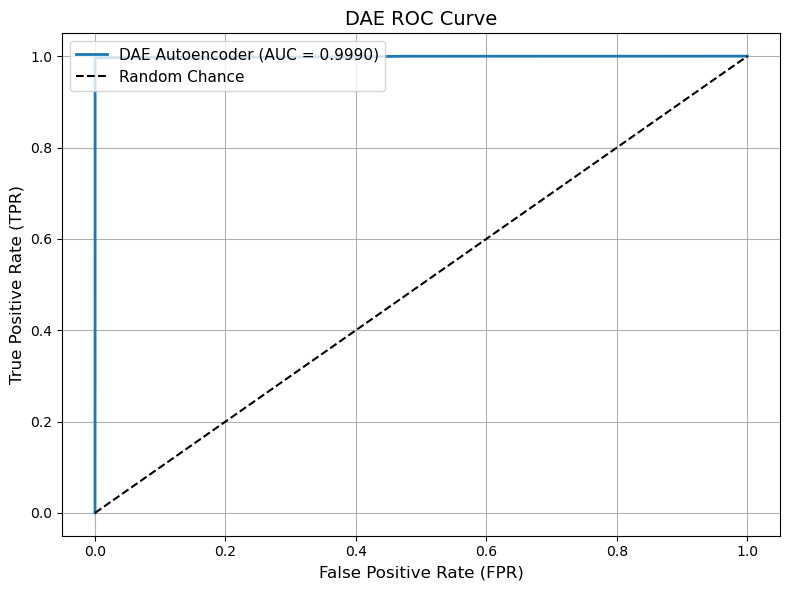

In [60]:

# 1. Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
# We use dae_scores because ROC curves require continuous scores/probabilities, not binary predictions.
fpr, tpr, thresholds = roc_curve(y_test_flat, dae_scores)
auc_score = roc_auc_score(y_test_flat, dae_scores)

# 2. Plotting configuration to match your image
plt.figure(figsize=(8, 6))

# Plot the DAE ROC curve
plt.plot(fpr, tpr, label=f'DAE Autoencoder (AUC = {auc_score:.4f})', color='tab:blue', linewidth=2)

# Plot the Random Chance diagonal line
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random Chance')

# 3. Graph formatting (Labels, Title, Grid, Legend)
plt.title('DAE ROC Curve', fontsize=14)
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True)
plt.legend(loc='upper left', fontsize=11)

# 4. Display or Save the plot
plt.tight_layout()
plt.show()
# If running headless or on a remote server, uncomment the line below to save it instead:
# plt.savefig('dae_roc_curve.png', dpi=300)

--- Training VQ-VAE ---
Epoch 1/30 Train Loss: 0.8932 Val Loss: 802760029.1091
Epoch 2/30 Train Loss: 1.4207 Val Loss: 802622719.5739
Epoch 3/30 Train Loss: 4.1297 Val Loss: 802280996.5253
Epoch 4/30 Train Loss: 8.7213 Val Loss: 801927443.4618
Epoch 5/30 Train Loss: 8.5222 Val Loss: 801934413.1220
Epoch 6/30 Train Loss: 6.7872 Val Loss: 802000150.8262
Epoch 7/30 Train Loss: 5.3129 Val Loss: 801958212.8169
Epoch 8/30 Train Loss: 4.0866 Val Loss: 801912684.8361
Epoch 9/30 Train Loss: 3.2571 Val Loss: 801817987.2367
Epoch 10/30 Train Loss: 2.6759 Val Loss: 801809169.7976
Epoch 11/30 Train Loss: 2.3989 Val Loss: 801774309.2895
Epoch 12/30 Train Loss: 2.2841 Val Loss: 801727795.5729
Epoch 13/30 Train Loss: 2.2407 Val Loss: 801672040.9230
Epoch 14/30 Train Loss: 2.2224 Val Loss: 801596532.1987
Epoch 15/30 Train Loss: 2.1801 Val Loss: 801519643.0134
Epoch 16/30 Train Loss: 2.1060 Val Loss: 801457718.0659
Epoch 17/30 Train Loss: 2.0259 Val Loss: 801417403.6923
Epoch 18/30 Train Loss: 1.9527 Va

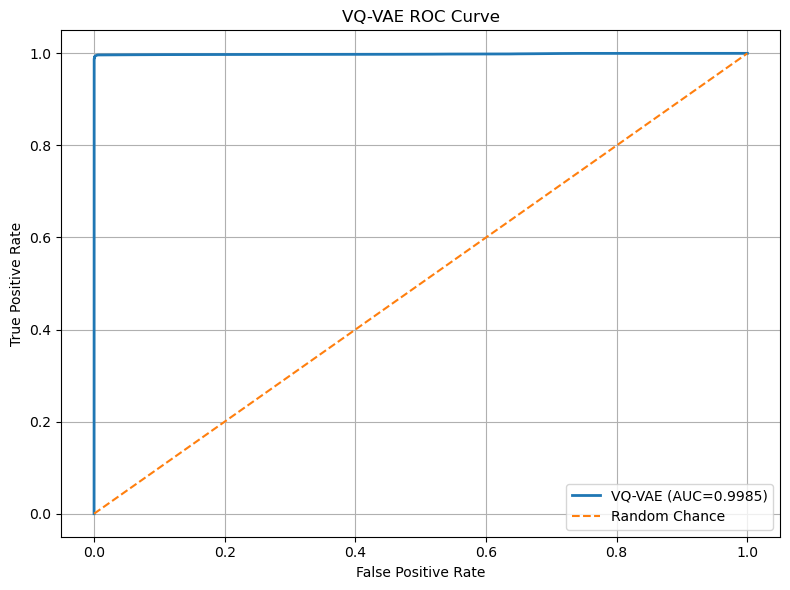

: 

In [ ]:
num_features = train_X.shape[1] 

flat_labels = test_Y.cpu().numpy().flatten()
# Execution routines
model = VQVAE(input_dim=num_features)
model = VQVAE(input_dim=num_features)

test_scores, preds, threshold, auc = train_and_test_vqvae(model, train_loader, val_loader, loader, val_Y_numpy, flat_labels, num_features, epochs=30
)

In [ ]:
# Extract parameters from your active workspace arrays
num_features = train_X.shape[1] 

GAE_Model = GraphAutoencoder(num_features)
# Execution routines
train_and_test_gae(GAE_Model, train_loader, val_loader, loader, val_Y_numpy, flat_labels, num_features, epochs=30)

--- Training Graph Autoencoder ---


In [ ]:
# improved_deep_model = DenoisingTabularAutoencoder(input_dim=train_X.shape[1])
# train_and_optimize_threshold(improved_deep_model,train_loader)

In [ ]:
rnn_model = AERNN(46572, train_X.shape[1], 256 , 8)
# model.apply(bias_init)
# model = model.to(device)

optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [ ]:
# 1. Initialize model with seq_len = 1 for your tabular row inputs
rnn_model = AERNN(seq_len=1, n_features=train_X.shape[1], latent_dim=256, hidden_size=8)

# 2. Correct the optimizer to target rnn_model
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=5e-3)
loss_fn = nn.MSELoss()

num_epochs = 30
print("Starting AERNN Training Loop...")

for epoch in range(num_epochs):
    rnn_model.train()
    train_loss = 0
    
    for batch in train_loader:
        x = batch[0] # Shape: (batch_size, n_features)
        
        # Reshape 2D tabular data to 3D sequential data: (batch_size, 1, n_features)
        x_seq = x.unsqueeze(1)
        
        optimizer.zero_grad()
        recon = rnn_model(x_seq)
        
        # Compute loss across all dimensions/features
        loss = loss_fn(recon, x_seq)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{num_epochs}, Avg Loss: {train_loss / len(train_loader):.4f}")

Starting AERNN Training Loop...
Epoch 1/30, Avg Loss: 0.0020
Epoch 2/30, Avg Loss: 0.0006
Epoch 3/30, Avg Loss: 0.0003
Epoch 4/30, Avg Loss: 0.0002
Epoch 5/30, Avg Loss: 0.0002
Epoch 6/30, Avg Loss: 0.0002
Epoch 7/30, Avg Loss: 0.0002
Epoch 8/30, Avg Loss: 0.0002
Epoch 9/30, Avg Loss: 0.0001
Epoch 10/30, Avg Loss: 0.0001
Epoch 11/30, Avg Loss: 0.0001


KeyboardInterrupt: 

In [ ]:
train_X

tensor([[ 0.5606, -0.4712,  0.5714,  ...,  0.0000, -0.0827, -0.8112],
        [-1.5133,  1.7715, -1.4728,  ...,  0.0000, -0.0827, -0.8112],
        [ 0.7026, -0.5171,  0.7113,  ...,  0.0000, -0.0827, -0.8112],
        ...,
        [ 0.1683, -0.0977,  0.2818,  ...,  0.0000, -0.0827,  0.2169],
        [ 0.3103, -0.7376,  0.3628,  ...,  0.0000, -0.0827,  0.7497],
        [ 0.1683, -0.7728,  0.2818,  ...,  0.0000, -0.0827,  0.2171]])

In [ ]:
def get_rnn_scores(model, loader, device):

    model.eval()

    scores = []

    with torch.no_grad():
        start_time = time.perf_counter()
        for batch in loader:

            x = batch[0].to(device)

            # Add sequence dimension
            x_seq = x.unsqueeze(1)

            recon = model(x_seq)

            # Reconstruction error per sample
            loss = F.mse_loss(
                recon,
                x_seq,
                reduction="none"
            ).sum(dim=-1).squeeze(-1)


            scores.extend(
                loss.cpu().numpy()
            )

    end_time = time.perf_counter()
    print(f"Execution Time: {end_time-start_time}")
    return np.asarray(scores)



# ==========================================
# Generate validation scores
# ==========================================

val_anomaly_scores = get_rnn_scores(
    rnn_model,
    val_loader,
    device
)


# Convert validation labels
if hasattr(val_Y, "cpu"):
    val_labels = val_Y.cpu().numpy().ravel().astype(int)
else:
    val_labels = np.asarray(val_Y).ravel().astype(int)



# ==========================================
# Find optimal threshold using validation set
# ==========================================

best_threshold = None
best_f1 = -1


thresholds = np.linspace(
    val_anomaly_scores.min(),
    val_anomaly_scores.max(),
    500
)


for threshold in thresholds:

    val_preds = (
        val_anomaly_scores >= threshold
    ).astype(int)


    score = f1_score(
        val_labels,
        val_preds,
        zero_division=0
    )


    if score > best_f1:
        best_f1 = score
        best_threshold = threshold



print(
    f"Best Validation Threshold: {best_threshold:.6f}"
)

print(
    f"Best Validation F1: {best_f1:.4f}"
)



# ==========================================
# Evaluate on Test Set
# ==========================================

test_anomaly_scores = get_rnn_scores(
    rnn_model,
    eval_loader,
    device
)


# Convert test labels
if hasattr(test_Y, "cpu"):
    test_labels = test_Y.cpu().numpy().ravel().astype(int)
else:
    test_labels = np.asarray(test_Y).ravel().astype(int)



# Apply frozen threshold
test_predictions = (
    test_anomaly_scores >= best_threshold
).astype(int)



# ==========================================
# Final Metrics
# ==========================================

auc = roc_auc_score(
    test_labels,
    test_anomaly_scores
)


print("\n--- AERNN Results ---")

print(
    f"ROC-AUC: {auc:.4f}"
)


print(
    classification_report(
        test_labels,
        test_predictions,
        zero_division=0
    )
)


print(
    f"Mean Reconstruction Error: {test_anomaly_scores.mean():.6f}"
)


Execution Time: 6.320824124966748
Best Validation Threshold: 0.001483
Best Validation F1: 0.7733
Execution Time: 11.246072042034939

--- AERNN Results ---
ROC-AUC: 0.9410
              precision    recall  f1-score   support

           0       0.97      0.92      0.95   1732049
           1       0.60      0.80      0.69    255138

    accuracy                           0.91   1987187
   macro avg       0.79      0.86      0.82   1987187
weighted avg       0.92      0.91      0.91   1987187

Mean Reconstruction Error: 0.001327


In [ ]:
# --- Update your dataset definitions ---
# Include both the features (data_X) and ground truth labels (data_Y)
# Change this line:
# data_Y = torch.tensor(data_y.values, dtype=torch.float32)

# # To this (flattens the 2D column into a clean 1D array):
# data_Y = torch.tensor(data_y.values, dtype=torch.float32).squeeze()
# eval_dataset = TensorDataset(data_X, data_Y)

# # Re-create your evaluation loader using the updated dataset
# eval_loader = DataLoader(eval_dataset, batch_size=512, shuffle=False)

In [ ]:
# import os
import time
import matplotlib.pyplot as plt
import seaborn as sns
import torch

def plot_loss_moment(losses):
    if not losses:
        print("No losses to plot.")
        return
    fig, ax = plt.subplots(figsize=(16, 9), dpi=80)
    ax.plot(losses, 'blue', label='train', linewidth=1)
    ax.set_title('Loss change in training')
    ax.set_ylabel('Loss')
    ax.set_xlabel('Iteration')
    ax.legend(loc='upper right')
    # Use a fallback if cf or cf.image_dir isn't defined in this scope
    # save_dir = cf.image_dir if 'cf' in globals() else '.'
    # plt.savefig(os.path.join(save_dir, 'loss_dagmm.png'))
    plt.close(fig)

# Model initialization
compressor = CompressNet(train_X.shape[1], 256, 128, 64, 32)
estimator = EstimateNet(34, 512, hyper_params.dropout_p, 2, hyper_params.lam1, hyper_params.lam2)

losses = []
loss_plot_interval = 20
steps = 0
loss_total = 0

compressor_opt = torch.optim.Adam(compressor.parameters(), lr=1e-3, amsgrad=True)
estimator_opt = torch.optim.Adam(estimator.parameters(), lr=1e-3, amsgrad=True)

print("Starting training debug run...")

# --- RESTRUCTURED TRAINING LOOP ---
for i in range(hyper_params.epoch_num):
    for batch in train_loader: # Using 'loader' as per your traceback line 86
        x = batch[0]  
        steps += 1

        # Forward Pass
        z, x_hat = compressor(x)
        loss = compressor.reconstruct_error(x, x_hat)

        gamma = estimator(z)
        loss += estimator.energy(gamma, z)
        loss_total += loss.detach().item()

        # Backward Pass & Optimization
        compressor_opt.zero_grad()
        estimator_opt.zero_grad()

        loss.backward()
        
        # Gradient clipping to ensure numerical safety
        torch.nn.utils.clip_grad_norm_(compressor.parameters(), max_norm=5.0)
        torch.nn.utils.clip_grad_norm_(estimator.parameters(), max_norm=5.0)
        
        compressor_opt.step()
        estimator_opt.step()

        if steps % loss_plot_interval == 0:
            print(f'Epoch: {i}  step: {steps}  loss: {loss_total/loss_plot_interval:.4f}')
            losses.append(loss_total / loss_plot_interval)
            loss_total = 0

Starting training debug run...
Epoch: 0  step: 20  loss: 4.6257
Epoch: 0  step: 40  loss: -4.0639
Epoch: 0  step: 60  loss: -4.0410
Epoch: 0  step: 80  loss: -1.7406
Epoch: 0  step: 100  loss: -0.5297
Epoch: 0  step: 120  loss: -1.4397
Epoch: 0  step: 140  loss: -0.2204
Epoch: 0  step: 160  loss: -0.1674
Epoch: 0  step: 180  loss: 0.4289
Epoch: 0  step: 200  loss: 1.6647
Epoch: 0  step: 220  loss: 3.8122
Epoch: 0  step: 240  loss: 5.5588
Epoch: 0  step: 260  loss: 2.3217
Epoch: 0  step: 280  loss: 0.4969
Epoch: 0  step: 300  loss: -0.6036
Epoch: 0  step: 320  loss: 1.2760
Epoch: 0  step: 340  loss: 4.0613
Epoch: 0  step: 360  loss: 1.7171
Epoch: 0  step: 380  loss: 1.7357
Epoch: 0  step: 400  loss: 1.8976
Epoch: 0  step: 420  loss: 2.8184
Epoch: 0  step: 440  loss: 1.4059
Epoch: 0  step: 460  loss: 1.1371
Epoch: 0  step: 480  loss: 0.9880
Epoch: 0  step: 500  loss: 0.8562
Epoch: 0  step: 520  loss: 0.3507
Epoch: 0  step: 540  loss: 0.1198
Epoch: 0  step: 560  loss: 2.0234
Epoch: 0  ste

In [ ]:

compressor.eval()
estimator.eval()

all_scores = []


with torch.no_grad():

    for batch in eval_loader:

        # Data only (no labels in loader)
        x = batch[0].to(device)


        # Encode input
        z, _ = compressor(x)


        # Mixture estimation
        gamma = estimator(z)

        m_prob = estimator.mixture_prob(gamma)
        m_mean = estimator.mixture_mean(gamma, z)
        m_cov = estimator.mixture_covar(
            gamma,
            z,
            m_mean
        )


        N, D = z.shape


        log_energies = torch.zeros(
            (N, estimator.mixture_dim),
            device=z.device
        )


        for k in range(estimator.mixture_dim):

            # Covariance determinant
            _, logdet = torch.linalg.slogdet(
                m_cov[k]
            )


            # Inverse covariance
            inv_cov = torch.linalg.pinv(
                m_cov[k]
            )


            # Mahalanobis distance
            diff = z - m_mean[k]

            mahalanobis = torch.sum(
                torch.matmul(diff, inv_cov) * diff,
                dim=1
            )


            # Gaussian log density
            log_density = -0.5 * (
                D * np.log(2 * np.pi)
                + logdet
                + mahalanobis
            )


            # Weighted mixture probability
            log_energies[:, k] = (
                torch.log(
                    m_prob[k] + 1e-8
                )
                + log_density
            )


        # DAGMM energy score
        batch_scores = (
            -torch.logsumexp(
                log_energies,
                dim=1
            )
            .cpu()
            .numpy()
        )


        all_scores.append(batch_scores)



# Combine all batches
final_scores = np.concatenate(all_scores)



# ==========================================
# Prepare Test Labels
# ==========================================

if hasattr(test_Y, "cpu"):

    final_labels = (
        test_Y
        .cpu()
        .numpy()
        .flatten()
        .astype(int)
    )

else:

    final_labels = (
        np.asarray(test_Y)
        .flatten()
        .astype(int)
    )



# ==========================================
# Apply Validation Threshold
# ==========================================

final_preds = (
    final_scores >= threshold
).astype(int)



# ==========================================
# Metrics
# ==========================================

print("================ DAGMM RESULTS ================")


print(
    "Label Distribution:",
    np.unique(
        final_labels,
        return_counts=True
    )
)


print(
    "Prediction Distribution:",
    np.unique(
        final_preds,
        return_counts=True
    )
)


print("\nClassification Report:")
print(
    classification_report(
        final_labels,
        final_preds,
        zero_division=0
    )
)


auc = roc_auc_score(
    final_labels,
    final_scores
)


print(
    f"\nROC-AUC Score: {auc:.4f}"
)


print(
    f"Mean Energy Score: {final_scores.mean():.6f}")

================ DAGMM RESULTS ================
Label Distribution: (array([0, 1]), array([1732049,  255138]))
Prediction Distribution: (array([0, 1]), array([1982060,    5127]))

Classification Report:
              precision    recall  f1-score   support

           0       0.87      1.00      0.93   1732049
           1       0.01      0.00      0.00    255138

    accuracy                           0.87   1987187
   macro avg       0.44      0.50      0.47   1987187
weighted avg       0.76      0.87      0.81   1987187


ROC-AUC Score: 0.4370
Mean Energy Score: -69.977348


In [ ]:
all_labels = []
for batch in loader:
    if len(batch) > 1:
        all_labels.extend(batch[1].cpu().numpy())
    else:
        all_labels.extend(np.zeros(batch[0].size(0)))

unique, counts = np.unique(all_labels, return_counts=True)
print("Label distribution in evaluation loader:")
print(dict(zip(unique, counts)))

Label distribution in evaluation loader:
{0.0: 1987187}


In [ ]:
nz = 100 # Size of the latent noise vector

generator_model = Generator(input_dim=nz, hidden_dim=128, output_dim=train_X.shape[1])
discriminator_model = Discriminator(input_dim=train_X.shape[1], hidden_dim=128)

# Re-setup Adam optimizers to point to the new parameters
optimizerD = torch.optim.Adam(discriminator_model.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = torch.optim.Adam(generator_model.parameters(), lr=0.0002, betas=(0.5, 0.999))


In [ ]:
# Initialize the ``BCELoss`` function
criterion = nn.BCELoss()

# Create batch of latent vectors that we will use to visualize
#  the progression of the generator
# fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.
lr = 0.0001

# Setup Adam optimizers for both G and D
optimizerD = torch.optim.Adam(discriminator_model.parameters(), lr=lr)
optimizerG = torch.optim.Adam(generator_model.parameters(), lr=lr)

In [ ]:
nz = 100


In [ ]:
import torch
import torch.nn as nn


def train_gan_anomaly_detector(
    netG,
    netD,
    train_loader,
    epochs,
    device,
    latent_dim=100
):

    netG = netG.to(device)
    netD = netD.to(device)


    criterion = nn.BCELoss()


    optimizerD = torch.optim.Adam(
        netD.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999)
    )


    optimizerG = torch.optim.Adam(
        netG.parameters(),
        lr=0.0002,
        betas=(0.5, 0.999)
    )


    G_losses = []
    D_losses = []


    print("Starting GAN anomaly detection training...")


    for epoch in range(epochs):

        for batch in train_loader:

            # ================================
            # Real normal samples
            # ================================

            real = batch[0].to(device)

            batch_size = real.size(0)


            real_labels = torch.ones(
                batch_size,
                device=device
            )

            fake_labels = torch.zeros(
                batch_size,
                device=device
            )


            # ================================
            # Train Discriminator
            # ================================

            netD.zero_grad()


            # Real normal traffic
            output_real = netD(real).view(-1)


            loss_real = criterion(
                output_real,
                real_labels
            )


            # Generate fake normal-like traffic
            noise = torch.randn(
                batch_size,
                latent_dim,
                device=device
            )


            fake = netG(noise)


            output_fake = netD(
                fake.detach()
            ).view(-1)


            loss_fake = criterion(
                output_fake,
                fake_labels
            )


            loss_D = loss_real + loss_fake


            loss_D.backward()

            optimizerD.step()



            # ================================
            # Train Generator
            # ================================

            netG.zero_grad()


            output_fake = netD(fake).view(-1)


            # Generator wants discriminator
            # to classify generated samples as real

            loss_G = criterion(
                output_fake,
                real_labels
            )


            loss_G.backward()

            optimizerG.step()



            G_losses.append(
                loss_G.item()
            )

            D_losses.append(
                loss_D.item()
            )


        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"D Loss: {loss_D.item():.4f} "
            f"G Loss: {loss_G.item():.4f}"
        )


    return netG, netD, G_losses, D_losses

In [ ]:
netD = Discriminator(input_dim=8)
netG = Generator(100,hidden_dim=256,output_dim=8)

In [ ]:
netG, netD, G_losses, D_losses = train_gan_anomaly_detector(
    netG,
    netD,
    train_loader,
    epochs=50,
    device=device,
    latent_dim=100
)

Starting GAN anomaly detection training...
Epoch [1/50] D Loss: 0.6020 G Loss: 1.7632
Epoch [2/50] D Loss: 0.5892 G Loss: 5.5615
Epoch [3/50] D Loss: 0.6919 G Loss: 5.9686


KeyboardInterrupt: 

In [ ]:
import torch
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    precision_recall_fscore_support,
    classification_report,
    f1_score
)


def get_anomaly_scores(discriminator_model, loader, device="cpu"):
    """
    Generates anomaly scores from discriminator.
    
    Assumption:
        Discriminator output:
        High value = normal
        Low value = anomaly
        
    Therefore:
        anomaly_score = 1 - discriminator_output
    """

    discriminator_model.eval()

    scores = []

    with torch.no_grad():

        for batch in loader:

            x = batch[0].to(device)

            outputs = discriminator_model(x).view(-1)

            # Convert normal probability into anomaly score
            anomaly_scores = 1.0 - outputs

            scores.extend(
                anomaly_scores.cpu().numpy()
            )

    return np.asarray(scores)



def find_best_threshold_pr(scores, y_true):
  # Calculate precision and recall across all meaningful thresholds
  precisions, recalls, thresholds = precision_recall_curve(y_true, scores)

  # Compute F1 scores safely avoiding zero division
  f1_scores = (
      2
      * (precisions * recalls)
      / np.maximum(precisions + recalls, 1e-8)
  )

  # Ignore the last threshold point (where recall = 0)
  best_idx = np.argmax(f1_scores[:-1])
  best_thresh = thresholds[best_idx]
  best_f1 = f1_scores[best_idx]

  # Fallback: If validation F1 is 0, default to contamination rate percentile
  if best_f1 == 0:
    contamination = np.mean(y_true)
    best_thresh = np.percentile(scores, 100 * (1 - contamination))

  return best_thresh



def evaluate_anomaly_detector(
    discriminator_model,
    val_loader,
    val_Y,
    test_loader,
    test_Y,
    device="cpu"
):

    discriminator_model = discriminator_model.to(device)


    # ==========================================
    # Validation Phase (Threshold Selection)
    # ==========================================

    val_scores = get_anomaly_scores(
        discriminator_model,
        val_loader,
        device
    )


    if hasattr(val_Y, "cpu"):
        val_labels = (
            val_Y.cpu()
            .numpy()
            .flatten()
            .astype(int)
        )
    else:
        val_labels = (
            np.asarray(val_Y)
            .flatten()
            .astype(int)
        )


    threshold, val_f1 = find_best_threshold(
        val_scores,
        val_labels
    )


    print(
        f"Best Validation Threshold: {threshold:.6f}"
    )

    print(
        f"Validation F1: {val_f1:.4f}"
    )



    # ==========================================
    # Test Phase
    # ==========================================

    test_scores = get_anomaly_scores(
        discriminator_model,
        test_loader,
        device
    )


    if hasattr(test_Y, "cpu"):
        test_labels = (
            test_Y.cpu()
            .numpy()
            .flatten()
            .astype(int)
        )
    else:
        test_labels = (
            np.asarray(test_Y)
            .flatten()
            .astype(int)
        )


    # Apply validation threshold
    predictions = (
        test_scores >= threshold
    ).astype(int)



    # ==========================================
    # Metrics
    # ==========================================

    auc_score = roc_auc_score(
        test_labels,
        test_scores
    )


    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            test_labels,
            predictions,
            average="binary",
            zero_division=0
        )
    )


    print("\n=== Semi-Supervised Evaluation Results ===")

    print(
        f"ROC-AUC Score: {auc_score:.4f}"
    )

    print(
        f"Precision: {precision:.4f}"
    )

    print(
        f"Recall:    {recall:.4f}"
    )

    print(
        f"F1-Score:  {f1:.4f}"
    )


    print("\nClassification Report:")
    print(
        classification_report(
            test_labels,
            predictions,
            target_names=[
                "Normal",
                "Anomaly"
            ],
            zero_division=0
        )
    )


    return {
        "auc": auc_score,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "threshold": threshold,
        "scores": test_scores,
        "labels": test_labels
    }

In [ ]:
# X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
# y_test_tensor = torch.tensor(y_test, dtype=torch.long)  # Or float32 depending on loss, long is standard for labels
# test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# # 3. Re-run your loader creation from before
# test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

In [ ]:
# 3. Pass THIS new loader into your evaluation function
results = evaluate_anomaly_detector(discriminator_model,val_loader,val_Y, eval_loader,test_Y, device="cpu")

Best Validation Threshold: 0.521354
Validation F1: 0.0054

=== Semi-Supervised Evaluation Results ===
ROC-AUC Score: 0.5255
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99    269049
     Anomaly       0.00      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.49      0.50      0.49    274268
weighted avg       0.96      0.98      0.97    274268



In [ ]:
# Assuming your test data loader returns (features, true_labels)
# where true_labels uses 0 for normal and 1 for attacks
# from torch.utils.data import DataLoader

# # Create the test_loader (adjust batch_size to match your training configuration)
# # test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

# # Now run the evaluation function
# # results = evaluate_anomaly_detector(discriminator_model, loader, device="cpu")

# results = evaluate_anomaly_detector(discriminator_model, loader, device="cpu")

In [ ]:
import sklearn.svm
from sklearn.linear_model import SGDOneClassSVM
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,f1_score,classification_report

# train_X, test_X, train_Y, test_Y = train_test_split(data_X.numpy(),data_Y.numpy(),test_size=0.2)

scaler = StandardScaler()
train_x_values = scaler.fit_transform(train_X)
test_x_values = scaler.transform(test_X)
val_x_values = scaler.transform(val_X)

model = SGDOneClassSVM(
    nu=0.05,
    random_state=42
)
print(train_X)
print()
model.fit(train_x_values)
val_scores = -model.decision_function(val_x_values)

start_time = time.perf_counter()
predictions = -model.decision_function(test_x_values)
predictions
# f1_score(test_Y,predictions)
mapped_predictions = np.where(predictions == -1, 1, 0)

# Now evaluate safely
# from sklearn.metrics import classification_report

print(classification_report(test_Y, mapped_predictions))
print("\nAUC Score:\n",roc_auc_score(test_Y, predictions))
end_time = time.perf_counter()
print(f"Execution Time: {end_time-start_time}")


tensor([[-0.4497, -0.1221, -0.3616,  ..., -0.0670, -0.0492, -1.0839],
        [-0.4545, -0.1202, -0.4359,  ..., -0.0670, -0.0492, -1.0839],
        [-0.4253,  0.0929, -0.4299,  ...,  0.0141, -0.0492, -1.0839],
        ...,
        [-0.4555, -0.1163, -0.4371,  ..., -0.0670, -0.0462, -0.3169],
        [-0.3930, -0.1171, -0.4383,  ..., -0.0670, -0.0462,  0.2544],
        [-0.4497, -0.1225, -0.3616,  ..., -0.0670, -0.0492,  2.6103]])



/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


              precision    recall  f1-score   support

         0.0       0.98      1.00      0.99    269049
         1.0       0.00      0.00      0.00      5219

    accuracy                           0.98    274268
   macro avg       0.49      0.50      0.50    274268
weighted avg       0.96      0.98      0.97    274268


AUC Score:
 0.08542433483990584
Execution Time: 0.25342845800332725


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
